# ============================================================
# PORT MODELLY du notebook optimisé (voir benchmarks/mesaVSmodelly/README.md)
# Mêmes paramètres, mêmes expériences, mêmes seeds que la version Mesa.
# ============================================================
# ABM — Comparaison Fraises × Cerises : Pression d'Invasion, Budgets TIS et Réaccouplement


In [1]:
# 1. IMPORTS & CONFIGURATION
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import modelly
import random
from dataclasses import dataclass
from typing import Optional, Dict, List, Tuple, Union

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
print("Modelly version :", modelly.__version__)

Mesa version : 2.3.2


In [2]:
# 2. PARAMÈTRES DE CULTURE (3 000 fruits chacune)
@dataclass
class CropParameters:
    name: str
    season_length: int
    total_fruits: int
    initial_fruits: int
    daily_fruit_production: int
    maturation_min: int
    maturation_max: int
    natural_lifespan_min: int
    natural_lifespan_max: int
    harvest_frequency: int
    prophylaxis_frequency: int

STRAWBERRY = CropParameters(
    name="strawberry", season_length=100, total_fruits=3000, initial_fruits=0,
    daily_fruit_production=30, maturation_min=2, maturation_max=4,
    natural_lifespan_min=7, natural_lifespan_max=14, harvest_frequency=3, prophylaxis_frequency=3
)

CHERRY = CropParameters(
    name="cherry", season_length=25, total_fruits=3000, initial_fruits=3000,
    daily_fruit_production=0, maturation_min=10, maturation_max=15,
    natural_lifespan_min=20, natural_lifespan_max=50, harvest_frequency=0, prophylaxis_frequency=0
)

In [3]:
# ============================================================
# GESTION DES DURÉES DE VIE (Loi normale tronquée à 1 jour minimum)
# ============================================================
LIFESPAN_MEANS = {
    "sterile": 7.0,
    "wild": 25.0,
    "female": 25.0,
}

LIFESPAN_CV = {
    "sterile": 0.30,
    "wild": 0.30,
    "female": 0.30,
}

def sample_lifespan(group, rng):
    """Tire une durée de vie entière dans une loi normale tronquée à 1 jour."""
    # FIX 5 : je passe le générateur du modèle (rng = model.random) au lieu de
    # taper dans np.random. Un np.random.normal() pour UN seul nombre coûte
    # 2 à 5 µs (validation des arguments, allocation d'un array...) là où
    # random.gauss() est à ~100 ns. On l'appelle à chaque naissance, ça compte.
    if group not in LIFESPAN_MEANS:
        raise ValueError(f"Groupe de durée de vie inconnu : {group}")

    mean = LIFESPAN_MEANS[group]
    sd = mean * LIFESPAN_CV[group]

    lifespan = rng.gauss(mean, sd)
    while lifespan < 1:
        lifespan = rng.gauss(mean, sd)

    return max(1, round(lifespan))


# modifier les temps de vie 

In [4]:
# 3. AGENTS DU MODÈLE
#
# Mes notes sur les fixes de perf (détail dans audit/PERF_AUDIT.md) :
#
#  FIX 1 : plus jamais `x in self.model.agents`. Sous Mesa 2.3.2 cette propriété
#          RECONSTRUIT un AgentSet complet (un WeakKeyDictionary sur tous les
#          agents) à chaque accès. Je faisais ça par agent, par slot, par kill...
#          92 % du temps d'une saison cerise partait là-dedans. Maintenant je
#          teste dans model.agents_[type] qui est un simple dict -> O(1).
#
#  FIX 5 : tout l'aléatoire passe par model.random (le random.Random que Mesa
#          seede depuis seed=). Les appels np.random scalaires sont 20 à 50x
#          plus lents qu'un random.random(). ATTENTION : random.randint(a, b)
#          est INCLUSIF sur b, np.random.randint(a, b) ne l'était pas. J'ai
#          décalé toutes les bornes hautes de -1 pour garder les mêmes lois.
#
#  FIX 6 : Fruit_Agent n'hérite plus de modelly.Agent. Un fruit n'a pas de step(),
#          ça ne servait qu'à mettre 3000 objets de plus dans la boucle d'agents
#          (et dans les reconstructions d'AgentSet du FIX 1).

import math

def _poisson(rng, lam):
    # FIX 5 : pas de Poisson dans le module random de la stdlib, donc Knuth.
    # Pour lambda = 6 c'est ~7 multiplications, bien plus rapide qu'un
    # np.random.poisson() appelé pour un seul tirage.
    L = math.exp(-lam)
    k, p = 0, 1.0
    while True:
        p *= rng.random()
        if p <= L:
            return k
        k += 1


class SterileMales_Agent(modelly.Agent):
    def __init__(self, model):
        super().__init__(model)
        self.creation_date = model.time
        rng = model.random
        total_lifespan = sample_lifespan("sterile", rng)
        initial_age = rng.randint(0, total_lifespan - 1) if model.time == 0 else 0
        self.death_date = model.time + (total_lifespan - initial_age)
        model.pop_sterile_males += 1

    def step(self):
        if self.model.time >= self.death_date:
            self.remove()
            self.model.pop_sterile_males = max(0, self.model.pop_sterile_males - 1)

class WildMales_Agent(modelly.Agent):
    def __init__(self, model):
        super().__init__(model)
        self.creation_date = model.time
        rng = model.random
        total_lifespan = sample_lifespan("wild", rng)
        initial_age = rng.randint(0, total_lifespan - 1) if model.time == 0 else 0
        self.death_date = model.time + (total_lifespan - initial_age)
        model.pop_wild_males += 1

    def step(self):
        if self.model.time >= self.death_date:
            self.remove()
            self.model.pop_wild_males = max(0, self.model.pop_wild_males - 1)

class Larvae_Agent(modelly.Agent):
    def __init__(self, model, sperm_selection, fruit=None):
        super().__init__(model)
        self.creation_date = model.time
        self.sperm_selection = sperm_selection
        self.fruit = fruit
        self.sex_ratio = 0.5
        self.death_date = self.mortality()
        # FIX 5 : était np.random.randint(6, 12) -> borne exclue, donc 6..11
        self.emergence_date = model.time + model.random.randint(6, 11)
        model.pop_larvae += 1
        model.cumulative_larvae_born += 1

    def mortality(self):
        # FIX 5 : np.random.binomial(1, p) pour un tirage de Bernoulli, c'était
        # le pire cas possible (5 fois par larve). `random() < p` fait
        # exactement la même chose pour 50x moins cher.
        r, t = self.model.random, self.model.time
        if r.random() < 0.132: return t + 1
        if r.random() < 0.087: return t + 2
        if r.random() < 0.048: return t + 3
        if r.random() < 0.100: return t + r.randint(4, 5)
        if r.random() < 0.056: return t + r.randint(7, 11)
        return None

    def kill(self):
        # FIX 1 : test d'appartenance dans le dict de Mesa, pas dans model.agents
        if self in self.model.agents:
            self.remove()
            self.model.pop_larvae = max(0, self.model.pop_larvae - 1)
        self.fruit = None

    def step(self):
        if self.death_date is not None and self.model.time >= self.death_date:
            self.kill()
            return
        if self.model.time >= self.emergence_date:
            self.kill()
            if self.model.random.random() < self.sex_ratio:
                WildMales_Agent(self.model)
            else:
                Females_Agent(self.model, self.sperm_selection, initial_mating_status="unmated")

class Females_Agent(modelly.Agent):
    def __init__(self, model, sperm_selection, initial_mating_status="unmated"):
        super().__init__(model)
        self.creation_date = model.time
        rng = model.random
        total_lifespan = sample_lifespan("female", rng)
        initial_age = rng.randint(0, total_lifespan - 1) if model.time == 0 else 0
        self.death_date = model.time + (total_lifespan - initial_age)

        self.time_until_next_mating = 0
        if initial_mating_status == "fertile":
            self.fertile_matings, self.sterile_matings = 1, 0
            self.first_mating, self.last_mating = 1, 1
        else:
            self.fertile_matings, self.sterile_matings = 0, 0
            self.first_mating, self.last_mating = None, None
        self.eggs_laid = 0
        self.eta, self.eta_sperm_choice, self.mean_eggs_per_day = 0.8, 0.59, 6
        self.RF_fertilized_min, self.RF_fertilized_max = 3, 13
        self.RF_sterilized_min, self.RF_sterilized_max = 4, 11
        self.sperm_selection = sperm_selection
        model.pop_females += 1

    def use_fertile_sperm(self):
        if self.fertile_matings == 0: return False
        if self.sperm_selection == "first": return self.first_mating == 1
        if self.sperm_selection == "last": return self.last_mating == 1
        rng = self.model.random
        if self.sperm_selection in ("mixed", "choice"):
            total = self.fertile_matings + self.sterile_matings
            return False if total == 0 else rng.random() < self.fertile_matings / total
        denom = self.fertile_matings + self.eta_sperm_choice * self.sterile_matings
        return False if denom == 0 else rng.random() < self.fertile_matings / denom

    def egglaying(self):
        rng = self.model.random
        number_eggs_laid = min(_poisson(rng, self.mean_eggs_per_day), 6)
        if number_eggs_laid <= 0: return

        # FIX 2 : avant je refaisais `[f for f in self.model.fruits if f.has_space()]`
        # pour CHAQUE femelle, CHAQUE jour : 3000 fruits parcourus x nb femelles.
        # 2,7 millions d'appels à has_space() sur une seule saison cerise.
        # Maintenant c'est le modèle qui tient la liste des fruits avec de la
        # place à jour, et je pioche dedans.
        pool = self.model.fruits_with_space
        if not pool: return

        # FIX 2 bis : np.random.choice() sur une liste d'objets copiait tout dans
        # un array puis permutait les 3000 fruits pour en prendre 6 max.
        # random.sample() c'est O(k).
        n_fruits = min(rng.randint(1, 6), number_eggs_laid, len(pool))
        selected_fruits = rng.sample(pool, n_fruits)
        eggs_per_fruit = [1] * n_fruits
        for _ in range(number_eggs_laid - n_fruits):
            avail = [j for j, f in enumerate(selected_fruits) if f.has_space()]
            if not avail: break
            eggs_per_fruit[rng.choice(avail)] += 1

        for fruit, n_eggs in zip(selected_fruits, eggs_per_fruit):
            for _ in range(n_eggs):
                if not fruit.can_receive_oviposition(): continue
                if self.use_fertile_sperm():
                    larva = Larvae_Agent(self.model, self.sperm_selection, fruit=fruit)
                    if fruit.add_oviposition("fertile", larva=larva): self.eggs_laid += 1
                    else: larva.kill()
                else:
                    if fruit.add_oviposition("sterile", larva=None): self.eggs_laid += 1

    def step(self):
        if self.model.time >= self.death_date:
            self.remove()
            self.model.pop_females = max(0, self.model.pop_females - 1)
            return
        rng = self.model.random
        if self.time_until_next_mating == 0:
            denom = self.model.pop_wild_males + self.eta * self.model.pop_sterile_males
            if denom > 0:
                if rng.random() < self.model.pop_wild_males / denom:
                    self.fertile_matings += 1
                    self.last_mating = 1
                    if self.first_mating is None: self.first_mating = 1
                    # FIX 5 : bornes hautes -1 (randint inclusif)
                    self.time_until_next_mating = rng.randint(self.RF_fertilized_min, self.RF_fertilized_max - 1)
                else:
                    self.sterile_matings += 1
                    self.last_mating = 0
                    if self.first_mating is None: self.first_mating = 0
                    self.time_until_next_mating = rng.randint(self.RF_sterilized_min, self.RF_sterilized_max - 1)
        else:
            self.time_until_next_mating -= 1
        self.egglaying()

class Fruit_Agent:
    # FIX 6 : plus de modelly.Agent ici. Le fruit garde un unique_id (le même
    # compteur que les autres) et une ref vers le modèle, c'est tout ce dont il
    # a besoin. Il n'est plus dans model.agents_, donc plus dans la boucle
    # d'agents du step, et il n'alourdit plus les AgentSet.
    def __init__(
        self, model, crop_parameters, capacity=20,
        young_puncture_probability=0.30, rotten_puncture_probability=0.10,
        rotten_threshold=5.0, larva_age_weight=0.5,
        rot_hazard_control=0.0, rot_hazard_sterile=0.2310, rot_hazard_fertile=0.3054
    ):
        self.unique_id = model.next_fruit_id()
        self.model = model
        self.crop, self.capacity = crop_parameters.name, capacity
        self.young_puncture_probability = young_puncture_probability
        self.rotten_puncture_probability = rotten_puncture_probability
        self.rotten_threshold, self.larva_age_weight = rotten_threshold, larva_age_weight
        self.rot_hazard_control = rot_hazard_control
        self.rot_hazard_sterile = rot_hazard_sterile
        self.rot_hazard_fertile = rot_hazard_fertile
        self.creation_date = model.time
        self.first_oviposition_date = None
        rng = model.random
        # FIX 5 : l'ancien np.random.randint(min, max + 1) == randint(min, max) inclusif
        self.maturation_age = rng.randint(crop_parameters.maturation_min, crop_parameters.maturation_max)
        self.natural_lifespan = rng.randint(crop_parameters.natural_lifespan_min, crop_parameters.natural_lifespan_max)
        self.slots = []
        # FIX 3 : compteurs entiers au lieu de re-sommer les slots à chaque lecture
        self.n_fertile = 0
        self.n_sterile = 0
        self.status = "young"
        # FIX 4 : je marque le fruit comme retiré, le modèle balaie en fin de step
        self.removed = False
        model.fruits.append(self)
        model.fruits_with_space.append(self)   # FIX 2

    @property
    def age(self): return self.model.time - self.creation_date
    @property
    def occupied(self): return len(self.slots)

    def has_space(self):
        return self.occupied < self.capacity

    def can_receive_oviposition(self):
        if not self.has_space(): return False
        rng = self.model.random
        if self.status == "young": return rng.random() < self.young_puncture_probability
        if self.status == "rotten": return rng.random() < self.rotten_puncture_probability
        return self.status == "harvestable"

    def add_oviposition(self, oviposition_type, larva=None):
        if not self.has_space(): return False
        # Si le fruit a déjà pourri, mettre à jour les catégories de pourriture cumulée
        if self.unique_id in self.model.rotten_fruit_ids:
            if oviposition_type == "fertile" and self.n_fertile == 0:
                if self.n_sterile > 0: self.model.cumulative_rotten_sterile_only -= 1
                else: self.model.cumulative_rotten_clean -= 1
                self.model.cumulative_rotten_with_larvae += 1
            elif oviposition_type == "sterile" and self.n_fertile == 0 and self.n_sterile == 0:
                self.model.cumulative_rotten_clean -= 1
                self.model.cumulative_rotten_sterile_only += 1

        self.slots.append({"type": oviposition_type, "larva": larva})
        if oviposition_type == "fertile": self.n_fertile += 1      # FIX 3
        else:                             self.n_sterile += 1
        if self.first_oviposition_date is None: self.first_oviposition_date = self.model.time
        # FIX 2 : le fruit vient de se remplir, je le sors du pool. list.remove()
        # est O(F) mais ça n'arrive qu'une fois dans la vie d'un fruit, rien à
        # voir avec le scan complet par femelle qu'on avait avant.
        if not self.has_space():
            self.model.fruits_with_space.remove(self)
        return True

    def check_status(self):
        if self.status == "rotten": return
        natural = self.age >= self.natural_lifespan
        hz = self.rot_hazard_fertile if self.n_fertile > 0 else (self.rot_hazard_sterile if self.n_sterile > 0 else 0.0)
        treatment = self.first_oviposition_date is not None and self.model.random.random() < (1.0 - math.exp(-hz))
        # FIX 1 : `s["larva"] in self.model.agents` reconstruisait l'AgentSet
        # pour CHAQUE slot de CHAQUE fruit. Je prends le dict des larves vivantes
        # une fois, et le test est O(1).
        alive = self.model.agents
        larva_ages = [self.model.time - s["larva"].creation_date for s in self.slots if s["type"] == "fertile" and s["larva"] in alive]
        rotten_score = sum(1.0 + self.larva_age_weight * a for a in larva_ages)
        infest = rotten_score >= self.rotten_threshold

        if natural or treatment or infest:
            self.status = "rotten"
            if self.unique_id not in self.model.rotten_fruit_ids:
                self.model.rotten_fruit_ids.add(self.unique_id)
                self.model.cumulative_rotten_fruits += 1
                if self.n_fertile > 0:
                    self.model.cumulative_rotten_with_larvae += 1
                elif self.n_sterile > 0:
                    self.model.cumulative_rotten_sterile_only += 1
                else:
                    self.model.cumulative_rotten_clean += 1
            return
        self.status = "harvestable" if self.age >= self.maturation_age else "young"

    def remove_from_model(self):
        for s in self.slots:
            if s["type"] == "fertile" and s["larva"] is not None: s["larva"].kill()
        # FIX 4 : avant, `self.model.fruits.remove(self)` parcourait les 3000
        # fruits pour CHAQUE fruit récolté -> la récolte était en O(F²). Là je
        # marque juste, et RematingModel.step() balaie une seule fois.
        self.removed = True


In [5]:
# 4. MODÈLE REMATINGMODEL COMPLET
class RematingModel(modelly.Model):
    def __init__(
        self, crop_parameters, num_agents_sterile=0, num_agents_wild=10, num_agents_larvae=0, num_agents_females=10,
        sperm_selection="preference", sterile_release_schedule=None,
        initial_female_mating_status="unmated", female_releases=None, female_release_mating_status="fertile",
        fruit_capacity=20, young_puncture_probability=0.30, rotten_puncture_probability=0.10,
        rotten_threshold=5.0, larva_age_weight=0.5,
        rot_hazard_control=0.0, rot_hazard_sterile=0.2310, rot_hazard_fertile=0.3054,
        harvest_fraction=0.90, prophylaxis_fraction=0.60, seed=None
    ):
        # FIX 5 : plus de np.random.seed(seed). Mesa lit seed= dans Model.__new__
        # et seede self.random avec. C'est ce générateur-là que tous les agents
        # utilisent maintenant, donc un seed = une trajectoire, comme avant.
        super().__init__(rng=seed)
        # Same random.Random(seed) stream as Mesa 2.3's Model.__new__
        # -> bit-identical trajectories for the same seed.
        self.random = random.Random(seed)
        self._fruit_id_counter = 0
        self.time, self.crop, self.sperm_selection = 0, crop_parameters, sperm_selection
        self.pop_sterile_males, self.pop_wild_males, self.pop_females, self.pop_larvae = 0, 0, 0, 0
        self.cumulative_larvae_born = 0
        self.fruits = []
        self.fruits_with_space = []   # FIX 2 : tenu à jour par Fruit_Agent + le balayage du step
        self.cumulative_harvested_fruits, self.cumulative_rotten_fruits, self.cumulative_prophylaxis_removed = 0, 0, 0
        self.cumulative_harvested_with_larvae, self.cumulative_harvested_sterile_only, self.cumulative_harvested_clean = 0, 0, 0
        self.cumulative_rotten_with_larvae = 0
        self.cumulative_rotten_sterile_only = 0
        self.cumulative_rotten_clean = 0
        self.rotten_fruit_ids = set()
        self.fruit_capacity = fruit_capacity
        self.young_puncture_probability, self.rotten_puncture_probability = young_puncture_probability, rotten_puncture_probability
        self.rotten_threshold, self.larva_age_weight = rotten_threshold, larva_age_weight
        self.rot_hazard_control, self.rot_hazard_sterile, self.rot_hazard_fertile = rot_hazard_control, rot_hazard_sterile, rot_hazard_fertile
        self.harvest_fraction, self.prophylaxis_fraction = harvest_fraction, prophylaxis_fraction
        self.sterile_release_schedule = sterile_release_schedule.copy() if sterile_release_schedule else {}
        self.total_sterile_released = 0
        self.female_releases = {int(k): int(v) for k, v in female_releases.items()} if isinstance(female_releases, dict) else {}
        self.female_release_mating_status = female_release_mating_status

        for _ in range(num_agents_sterile): SterileMales_Agent(self)
        for _ in range(num_agents_wild): WildMales_Agent(self)
        for _ in range(num_agents_larvae): Larvae_Agent(self, sperm_selection)
        for _ in range(num_agents_females): Females_Agent(self, sperm_selection, initial_mating_status=initial_female_mating_status)
        for _ in range(crop_parameters.initial_fruits): self.create_fruit()

        # FIX 3 : les 5 compteurs de fruits sortent d'UN seul passage (_fruit_census),
        # fait dans collect_data(). Avant c'était 5 lambdas qui rebalayaient chacune
        # tous les fruits, et 3 d'entre elles re-sommaient les slots de chaque fruit.
        self.datacollector = modelly.DataCollector(
            model_reporters={
                "Time": lambda m: m.time,
                "Wild_males": lambda m: m.pop_wild_males,
                "Sterile_males": lambda m: m.pop_sterile_males,
                "Females": lambda m: m.pop_females,
                "Larvae": lambda m: m.pop_larvae,
                "Young_fruits": lambda m: m._census[0],
                "Harvestable_fruits": lambda m: m._census[1],
                "Rotten_natural": lambda m: m._census[2],
                "Rotten_sterile_only": lambda m: m._census[3],
                "Rotten_larvae": lambda m: m._census[4],
                "Harvested_cumul": lambda m: m.cumulative_harvested_fruits,
                "Rotten_cumul": lambda m: m.cumulative_rotten_fruits
            }
        )
        self.collect_data()

    def next_fruit_id(self):
        """Return the next fruit id (fruits are plain objects, not Modelly agents)."""
        uid = self._fruit_id_counter
        self._fruit_id_counter += 1
        return uid

    def create_fruit(self):
        return Fruit_Agent(
            self, self.crop, capacity=self.fruit_capacity,
            young_puncture_probability=self.young_puncture_probability,
            rotten_puncture_probability=self.rotten_puncture_probability,
            rotten_threshold=self.rotten_threshold, larva_age_weight=self.larva_age_weight,
            rot_hazard_control=self.rot_hazard_control, rot_hazard_sterile=self.rot_hazard_sterile,
            rot_hazard_fertile=self.rot_hazard_fertile
        )

    def harvest(self, fraction=None):
        if fraction is None: fraction = self.harvest_fraction
        harvestable = [f for f in self.fruits if f.status == "harvestable"]
        if not harvestable: return 0
        n = int(fraction * len(harvestable))
        if n <= 0: return 0
        # FIX 4 : random.sample au lieu de np.random.choice (copie en array +
        # permutation complète). Et remove_from_model ne fait plus que marquer.
        for f in self.random.sample(harvestable, n):
            if f.n_fertile > 0: self.cumulative_harvested_with_larvae += 1
            elif f.n_sterile > 0: self.cumulative_harvested_sterile_only += 1
            else: self.cumulative_harvested_clean += 1
            f.remove_from_model()
        self.cumulative_harvested_fruits += n
        return n

    def prophylaxis(self, fraction=None):
        if fraction is None: fraction = self.prophylaxis_fraction
        rotten = [f for f in self.fruits if f.status == "rotten"]
        if not rotten: return 0
        n = int(fraction * len(rotten))
        if n <= 0: return 0
        for f in self.random.sample(rotten, n): f.remove_from_model()   # FIX 4
        self.cumulative_prophylaxis_removed += n
        return n

    def _fruit_census(self):
        # FIX 3 : un seul passage sur les fruits pour les 5 catégories
        young = ripe = rot_nat = rot_ster = rot_larv = 0
        for f in self.fruits:
            if   f.status == "young":       young += 1
            elif f.status == "harvestable": ripe += 1
            elif f.n_fertile > 0:           rot_larv += 1
            elif f.n_sterile > 0:           rot_ster += 1
            else:                           rot_nat += 1
        return young, ripe, rot_nat, rot_ster, rot_larv

    def collect_data(self):
        # FIX 3 : plus de check_status() ici ! Il tournait DEUX fois par jour
        # (ici + dans step), donc le tirage du hazard de pourrissement
        # `random() < 1 - exp(-hz)` se faisait deux fois par jour. Le p effectif
        # était 1-(1-p)^2 : 0.46 au lieu de 0.26 pour fertile, 0.38 au lieu de
        # 0.21 pour stérile. Ça gonflait direct la métrique "pourris piqûres
        # stériles seules". Un seul passage par jour, dans step().
        self._census = self._fruit_census()
        self.datacollector.collect(self)

    def advance_day(self):
        if self.crop.daily_fruit_production > 0:
            for _ in range(self.crop.daily_fruit_production): self.create_fruit()
        n_ster = int(self.sterile_release_schedule.get(self.time, 0))
        for _ in range(n_ster): SterileMales_Agent(self)
        self.total_sterile_released += n_ster
        n_fem = int(self.female_releases.get(self.time, 0))
        for _ in range(n_fem): Females_Agent(self, self.sperm_selection, initial_mating_status=self.female_release_mating_status)

        # FIX 1 + 6 : avant c'était `list(self.agents)` puis `if a in self.agents`
        # pour CHAQUE agent -> l'AgentSet était reconstruit N fois par step, O(N²).
        # Je prends un snapshot direct des dicts internes (pas de WeakKeyDictionary
        # du tout), et le test de vie se fait dans ces mêmes dicts en O(1).
        # Les fruits ne sont plus des modelly.Agent, donc ils ne sont plus là-dedans.
        # Mesa 2.3 iterates agents_ grouped by type; Modelly's agents_by_type
        # keeps that same order, so the shuffle consumes the same RNG stream.
        agents = [a for bucket in self.agents_by_type.values() for a in bucket]
        self.random.shuffle(agents)   # FIX 5 : np.random.shuffle sur une liste d'objets = boucle Python
        for a in agents:
            if a in self.agents: a.step()

        for f in self.fruits: f.check_status()   # FIX 3 : le seul appel de la journée
        if self.crop.harvest_frequency > 0 and self.time > 0 and self.time % self.crop.harvest_frequency == 0: self.harvest()
        if self.crop.name == "cherry" and self.time == self.crop.season_length - 1: self.harvest()
        if self.crop.prophylaxis_frequency > 0 and self.time > 0 and self.time % self.crop.prophylaxis_frequency == 0: self.prophylaxis()

        # FIX 4 : balayage unique des fruits retirés par la récolte / prophylaxie,
        # et reconstruction du pool des fruits avec de la place (FIX 2).
        self.fruits = [f for f in self.fruits if not f.removed]
        self.fruits_with_space = [f for f in self.fruits if f.has_space()]

        self.collect_data()
        self.time += 1

    def get_model_dataframe(self): return self.datacollector.get_model_vars_dataframe()


In [6]:
# 5. CALENDRIERS TIS & FONCTION D'EXPÉRIMENTATION

def continuous_schedule(budget, season_length):
    base, rem = budget // season_length, budget % season_length
    return {day: base + (1 if day < rem else 0) for day in range(season_length)}

def periodic_schedule(budget, season_length, interval, first_day=0):
    days = list(range(first_day, season_length, interval))
    base, rem = budget // len(days), budget % len(days)
    return {day: base + (1 if i < rem else 0) for i, day in enumerate(days)}

def front_loaded_schedule(budget, season_length, initial_fraction=0.70, maintenance_interval=7):
    if initial_fraction == 1.00: return {0: budget}
    init = int(round(budget * initial_fraction))
    rem = budget - init
    days = list(range(maintenance_interval, season_length, maintenance_interval))
    sched = {0: init}
    if rem > 0 and days:
        base, r = rem // len(days), rem % len(days)
        for i, d in enumerate(days): sched[d] = base + (1 if i < r else 0)
    elif rem > 0: sched[0] += rem
    return sched

def make_strategies(budget, season_length):
    if budget == 0:
        return {"No TIS": {}}
    return {
        "Daily": continuous_schedule(budget, season_length),
        "Every 3 days": periodic_schedule(budget, season_length, 3),
        "Every 7 days": periodic_schedule(budget, season_length, 7),
        "70% init + 7d maint": front_loaded_schedule(budget, season_length, 0.70, 7),
        "100% init": front_loaded_schedule(budget, season_length, 1.00, 0),
    }

def run_factorial_experiment(
    crops, invasions_dict, budgets, remating_modes,
    n_reps=10, base_seed=100
):
    records = []
    total_comb = len(crops) * len(invasions_dict) * len(budgets) * len(remating_modes)
    count = 0
    
    for crop in crops:
        for inv_name, pop in invasions_dict.items():
            for rem_mode in remating_modes:
                for b in budgets:
                    strats = make_strategies(b, crop.season_length)
                    for s_name, sched in strats.items():
                        for rep in range(n_reps):
                            seed = base_seed + rep * 1000 + b * 7 + len(s_name) * 13 + len(inv_name) * 19
                            model = RematingModel(
                                crop_parameters=crop,
                                sterile_release_schedule=sched,
                                num_agents_wild=pop["wild"],
                                num_agents_females=pop["females"],
                                sperm_selection=rem_mode,
                                rotten_puncture_probability=0.10,
                                seed=seed
                            )
                            for _ in range(crop.season_length): model.advance_day()
                            tot = crop.total_fruits
                            
                            records.append({
                                "Crop": crop.name,
                                "Invasion": inv_name,
                                "Budget": b,
                                "Remating": rem_mode,
                                "Strategy": s_name,
                                "Replicate": rep,
                                "Harvested - clean (%)": 100 * model.cumulative_harvested_clean / tot,
                                "Harvested - sterile only (%)": 100 * model.cumulative_harvested_sterile_only / tot,
                                "Harvested - larvae (%)": 100 * model.cumulative_harvested_with_larvae / tot,
                                "Harvested (%)": 100 * model.cumulative_harvested_fruits / tot,
                                "Rotten (%)": 100 * model.cumulative_rotten_fruits / tot,
                                "Rotten - larvae (%)": 100 * model.cumulative_rotten_with_larvae / tot,
                                "Rotten - sterile only (%)": 100 * model.cumulative_rotten_sterile_only / tot,
                                "Rotten - clean (%)": 100 * model.cumulative_rotten_clean / tot,
                                "Larvae produced": model.cumulative_larvae_born
                            })
                    count += 1
                    print(f"Progression : {count} / {total_comb} blocs exécutés.")
    return pd.DataFrame(records)

Lancement du test rapide sur Fraise (100 jours, 1 réplicat par stratégie)...
Test terminé avec succès !



,Stratégie,Budget,Récoltés sains (%),Pourris totaux (%),Pourris larves (%),Pourris stériles (%),Larves produites
0,No TIS,0,58.9,24.6,24.1,0.0,1763
1,Daily,300,82.5,8.2,3.9,2.9,236
2,Every 3 days,300,83.0,8.4,2.7,4.4,190
3,Every 7 days,300,88.5,5.3,2.2,1.5,131
4,70% init + 7d maint,300,88.5,4.8,0.6,2.8,43
5,100% init,300,73.4,14.8,11.6,2.2,837


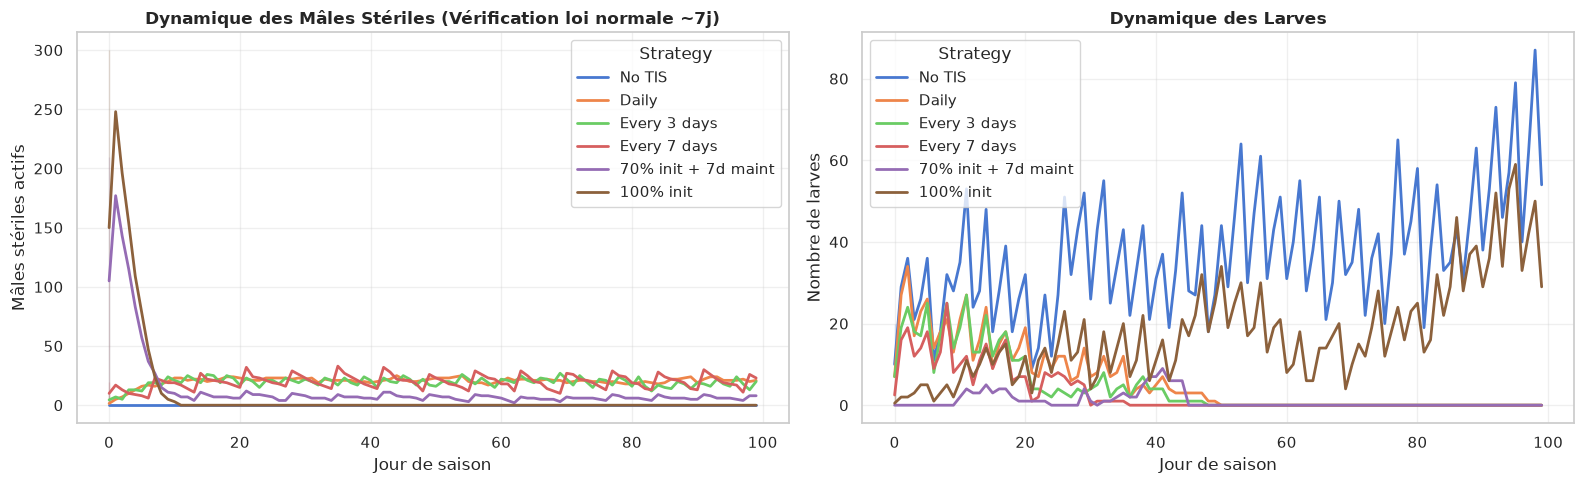

In [7]:
# ============================================================
# CELLULE DE TEST RAPIDE : 1 RÉPÉTITION FRAISE PAR SCÉNARIO
# ============================================================
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

test_budget = 300
test_invasion = {"wild": 10, "females": 10}  # Invasion Moyenne
test_remating = "preference"

# Récupération du témoin (Budget 0) et des 5 stratégies (Budget 300)
strategies_test = {"No TIS": {}}
strategies_test.update(make_strategies(test_budget, STRAWBERRY.season_length))

summary_records = []
temporal_dfs = []

print("Lancement du test rapide sur Fraise (100 jours, 1 réplicat par stratégie)...")

for s_name, sched in strategies_test.items():
    b_val = 0 if s_name == "No TIS" else test_budget
    model = RematingModel(
        crop_parameters=STRAWBERRY,
        sterile_release_schedule=sched,
        num_agents_wild=test_invasion["wild"],
        num_agents_females=test_invasion["females"],
        sperm_selection=test_remating,
        rotten_puncture_probability=0.10,
        seed=42
    )
    
    for _ in range(STRAWBERRY.season_length):
        model.advance_day()
        
    tot = STRAWBERRY.total_fruits
    summary_records.append({
        "Stratégie": s_name,
        "Budget": b_val,
        "Récoltés sains (%)": round(100 * model.cumulative_harvested_clean / tot, 1),
        "Pourris totaux (%)": round(100 * model.cumulative_rotten_fruits / tot, 1),
        "Pourris larves (%)": round(100 * model.cumulative_rotten_with_larvae / tot, 1),
        "Pourris stériles (%)": round(100 * model.cumulative_rotten_sterile_only / tot, 1),
        "Larves produites": model.cumulative_larvae_born
    })
    
    df_temp = model.get_model_dataframe()
    df_temp["Strategy"] = s_name
    temporal_dfs.append(df_temp)

print("Test terminé avec succès !\n")

# 1. Affichage du tableau bilan
test_summary_df = pd.DataFrame(summary_records)
display(test_summary_df)

# 2. Vérification visuelle rapide des dynamiques (Mâles stériles et Larves)
test_dyn_df = pd.concat(temporal_dfs, ignore_index=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.lineplot(data=test_dyn_df, x="Time", y="Sterile_males", hue="Strategy", ax=axes[0], linewidth=2)
axes[0].set_title("Dynamique des Mâles Stériles (Vérification loi normale ~7j)", fontweight="bold")
axes[0].set_xlabel("Jour de saison")
axes[0].set_ylabel("Mâles stériles actifs")
axes[0].grid(True, alpha=0.3)

sns.lineplot(data=test_dyn_df, x="Time", y="Larvae", hue="Strategy", ax=axes[1], linewidth=2)
axes[1].set_title("Dynamique des Larves", fontweight="bold")
axes[1].set_xlabel("Jour de saison")
axes[1].set_ylabel("Nombre de larves")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [8]:
# 6. CONFIGURATION, LANCEMENT (OU CACHE CSV)
import os
import pandas as pd

CSV_FILE = "resultats_experience_factorielle.csv"
FORCE_RERUN = True  # Mettre à True pour recalculer avec les nouvelles métriques détaillées de pourrissement

if os.path.exists(CSV_FILE) and not FORCE_RERUN:
    print(f"Chargement des données depuis '{CSV_FILE}'...")
    exp_df = pd.read_csv(CSV_FILE)
    print(f"{len(exp_df)} lignes rechargées avec succès !")
else:
    INVASIONS = {
        "Faible (3 W : 3 F)":  {"wild": 3, "females": 3},
        "Moyenne (10 W : 10 F)": {"wild": 10, "females": 10},
        "Forte (30 W : 30 F)":  {"wild": 30, "females": 30}
    }
    BUDGETS = [0, 150, 300, 600]
    REMATING_MODES = ["preference", "first"]
    N_REPS = 3

    print("Lancement de l'expérience factorielle...")
    exp_df = run_factorial_experiment(
        crops=[STRAWBERRY, CHERRY],
        invasions_dict=INVASIONS,
        budgets=BUDGETS,
        remating_modes=REMATING_MODES,
        n_reps=N_REPS,
        base_seed=42
    )
    exp_df.to_csv(CSV_FILE, index=False)
    print(f"Simulations terminées et enregistrées dans '{CSV_FILE}' !")

Lancement de l'expérience factorielle...
Progression : 1 / 48 blocs exécutés.
Progression : 2 / 48 blocs exécutés.
Progression : 3 / 48 blocs exécutés.
Progression : 4 / 48 blocs exécutés.
Progression : 5 / 48 blocs exécutés.
Progression : 6 / 48 blocs exécutés.
Progression : 7 / 48 blocs exécutés.
Progression : 8 / 48 blocs exécutés.
Progression : 9 / 48 blocs exécutés.
Progression : 10 / 48 blocs exécutés.
Progression : 11 / 48 blocs exécutés.
Progression : 12 / 48 blocs exécutés.
Progression : 13 / 48 blocs exécutés.
Progression : 14 / 48 blocs exécutés.
Progression : 15 / 48 blocs exécutés.
Progression : 16 / 48 blocs exécutés.
Progression : 17 / 48 blocs exécutés.
Progression : 18 / 48 blocs exécutés.
Progression : 19 / 48 blocs exécutés.
Progression : 20 / 48 blocs exécutés.
Progression : 21 / 48 blocs exécutés.
Progression : 22 / 48 blocs exécutés.
Progression : 23 / 48 blocs exécutés.
Progression : 24 / 48 blocs exécutés.
Progression : 25 / 48 blocs exécutés.
Progression : 26 /

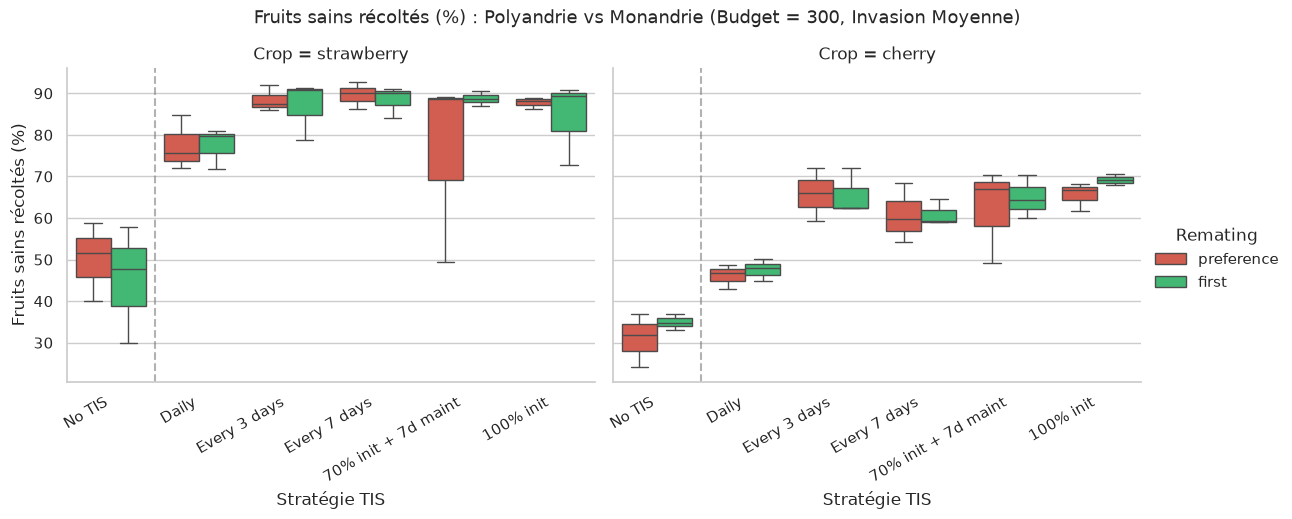

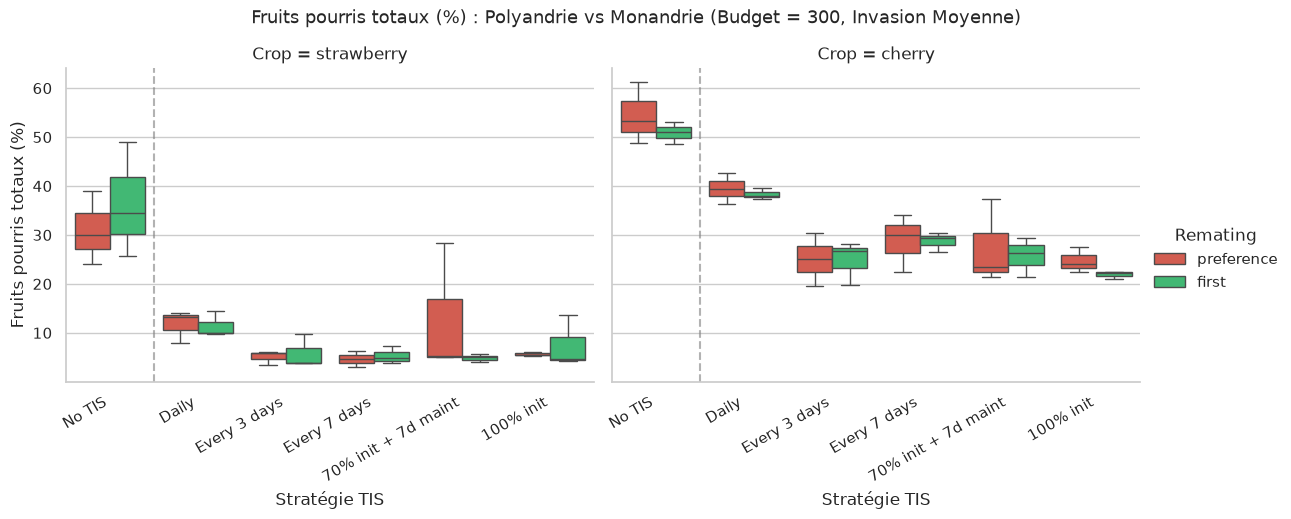

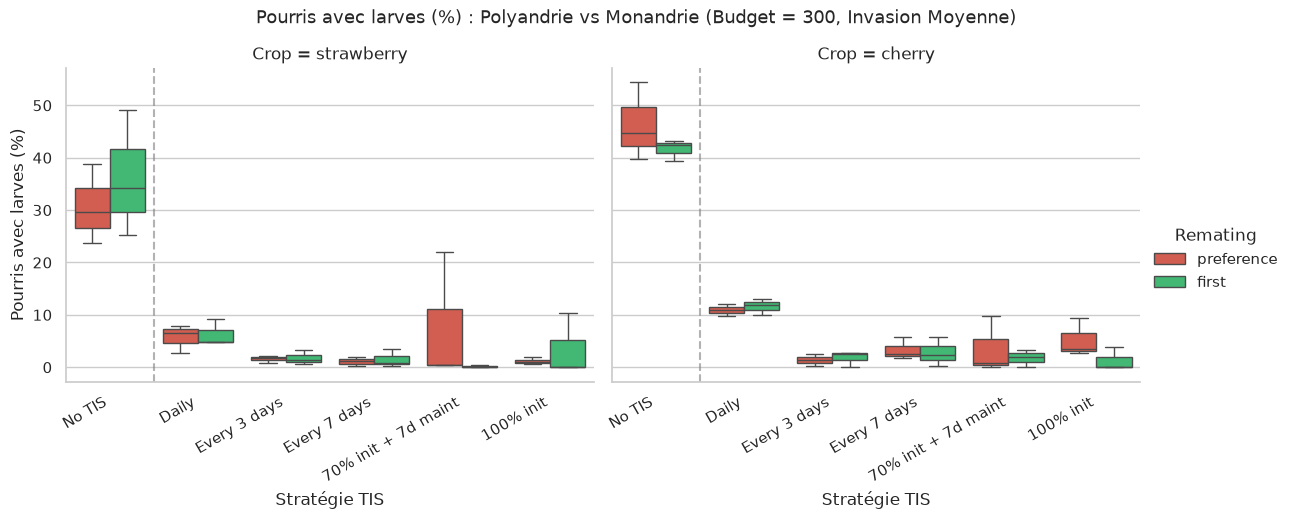

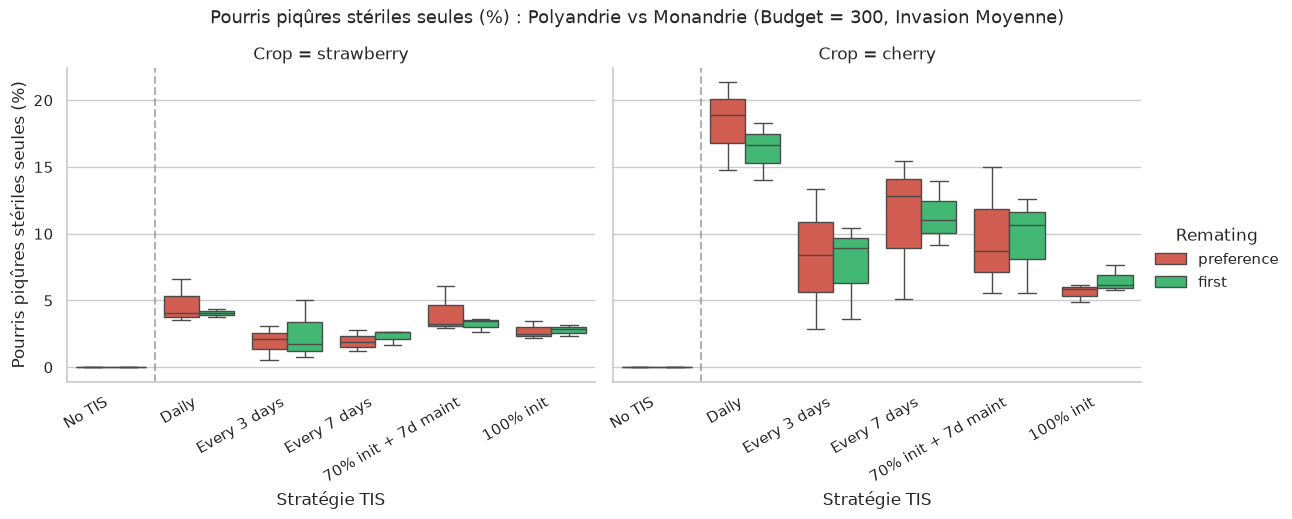

In [9]:
# 7. VISUALISATION 1 : FRUITS SAINS ET POURRISSEMENTS DÉTAILLÉS
strat_order = ['No TIS', 'Daily', 'Every 3 days', 'Every 7 days', '70% init + 7d maint', '100% init']

sub_remating = exp_df[
    (exp_df["Invasion"] == "Moyenne (10 W : 10 F)") & 
    ((exp_df["Budget"] == 300) | (exp_df["Strategy"] == "No TIS"))
].copy()

metrics_to_plot = [
    ("Harvested - clean (%)", "Fruits sains récoltés (%)"),
    ("Rotten (%)", "Fruits pourris totaux (%)"),
    ("Rotten - larvae (%)", "Pourris avec larves (%)"),
    ("Rotten - sterile only (%)", "Pourris piqûres stériles seules (%)")
]

for metric_col, metric_title in metrics_to_plot:
    if metric_col not in sub_remating.columns: continue
    g = sns.catplot(
        data=sub_remating,
        x="Strategy", y=metric_col, hue="Remating",
        order=[s for s in strat_order if s in sub_remating["Strategy"].unique()],
        col="Crop", kind="box",
        palette={"preference": "#e74c3c", "first": "#2ecc71"},
        height=4.5, aspect=1.3
    )
    g.set_xticklabels(rotation=30, ha="right")
    g.set_axis_labels("Stratégie TIS", metric_title)
    g.fig.subplots_adjust(top=0.85)
    g.fig.suptitle(f"{metric_title} : Polyandrie vs Monandrie (Budget = 300, Invasion Moyenne)", fontsize=13)
    for ax in g.axes.flat: ax.axvline(0.5, color='gray', linestyle='--', alpha=0.6)
    plt.show()

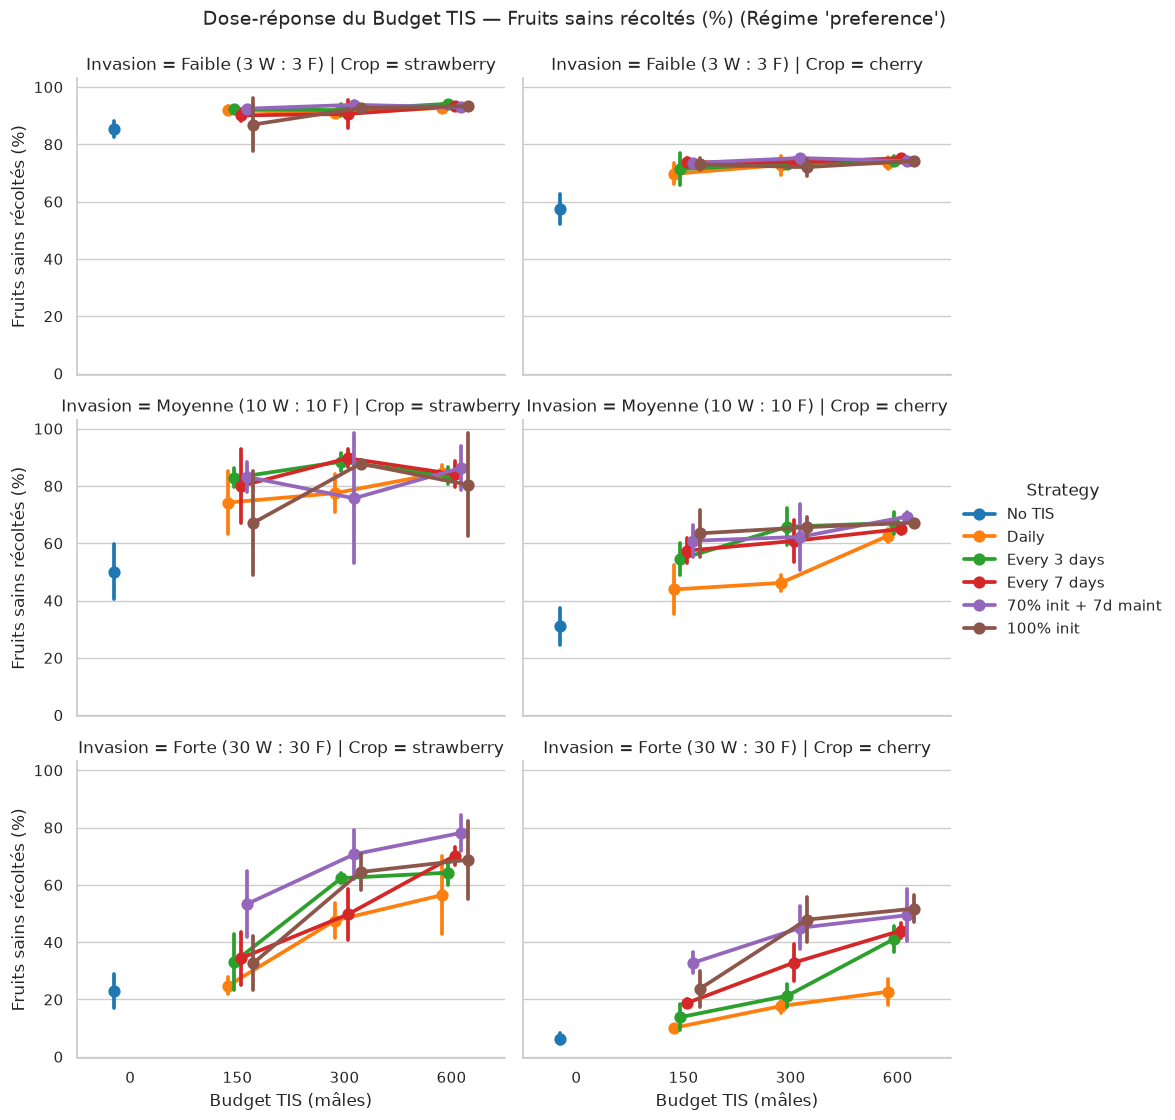

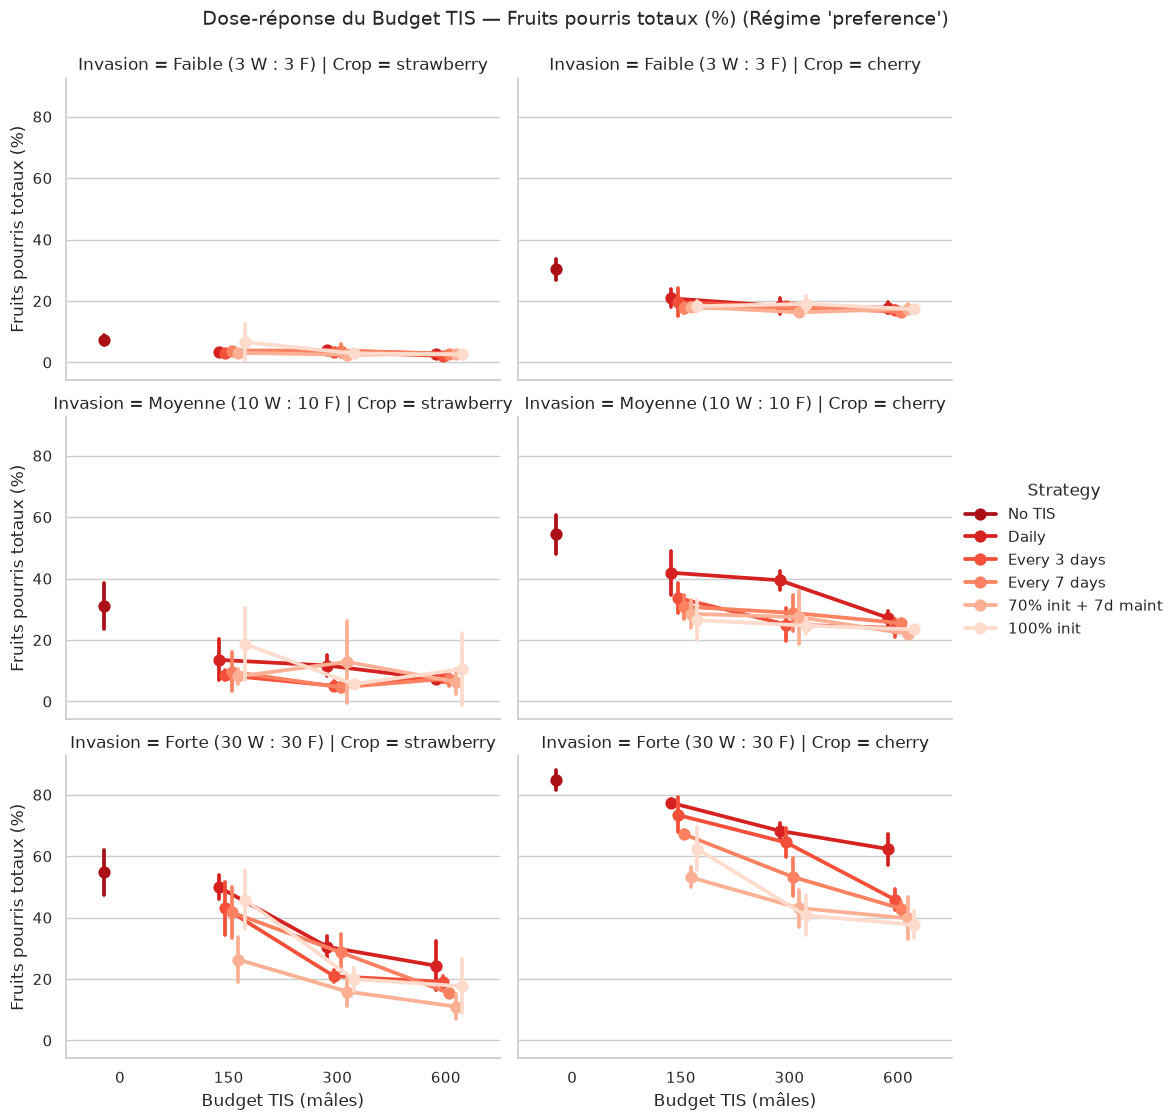

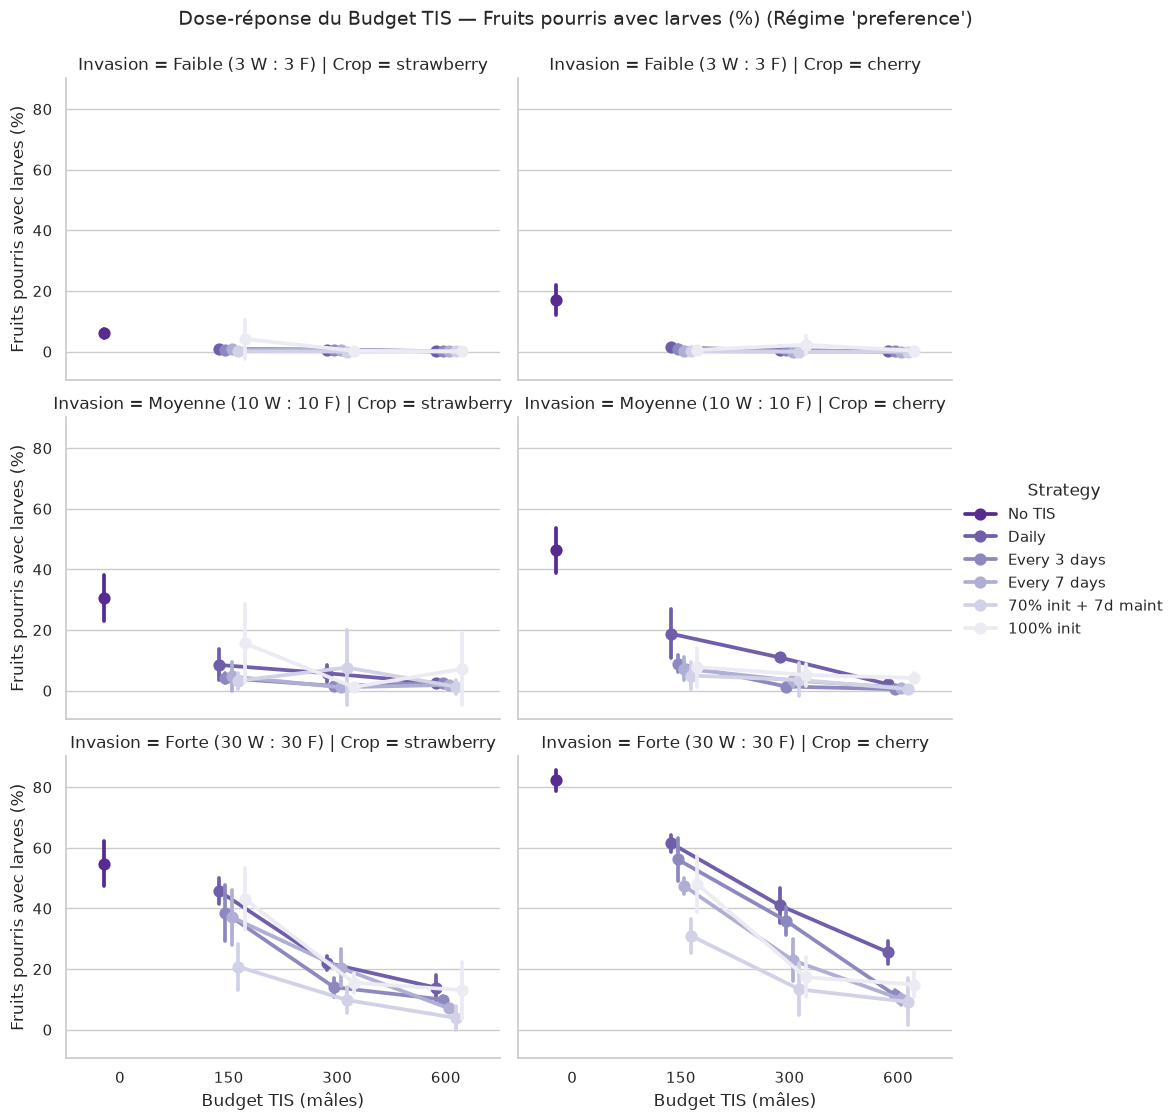

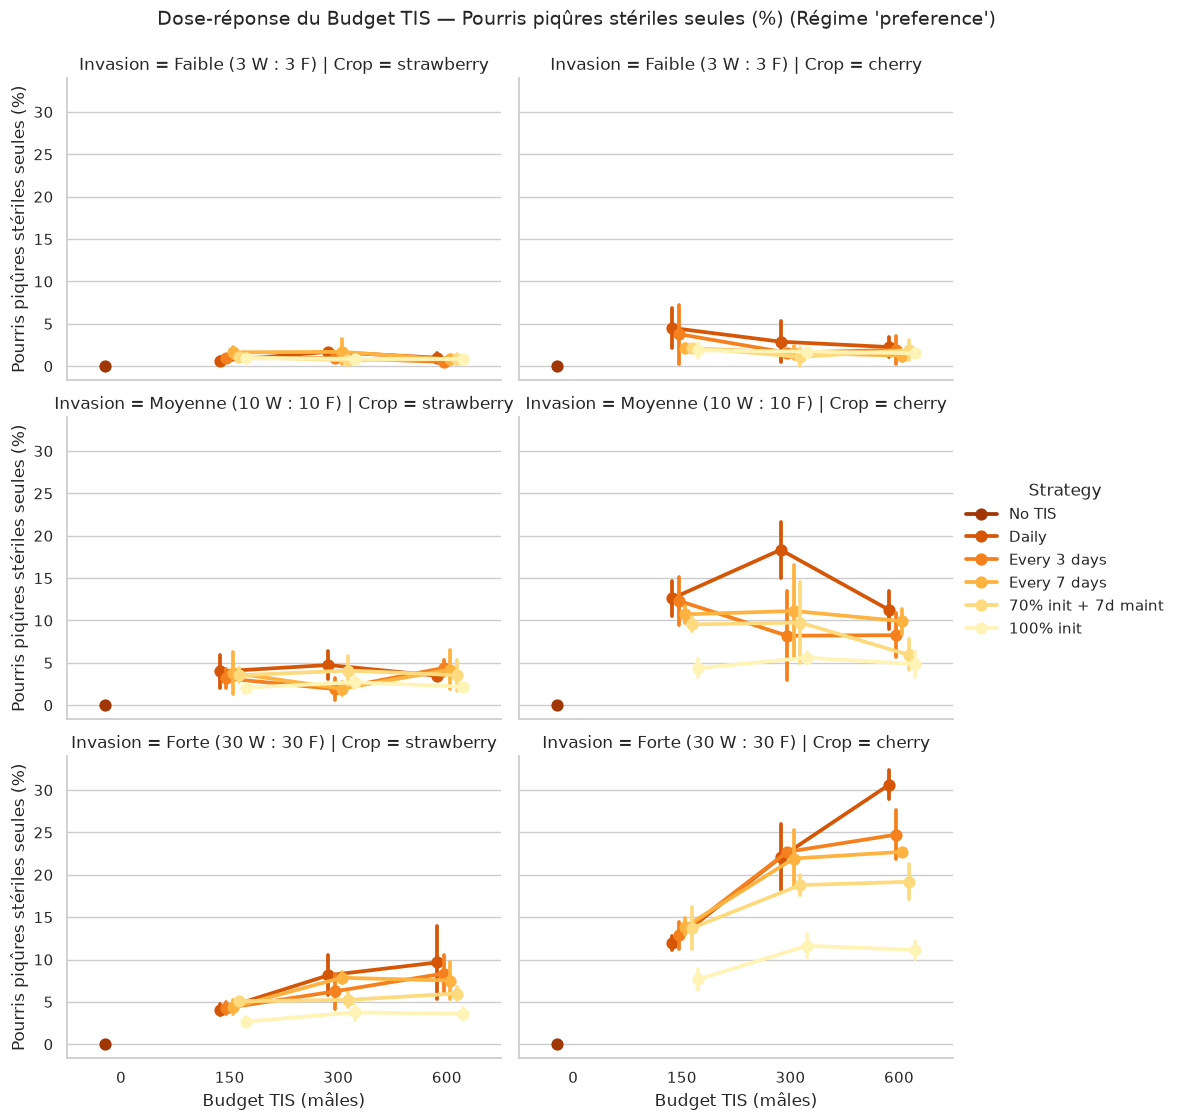

In [10]:
# 8. VISUALISATION 2 : DOSE-RÉPONSE DU BUDGET SELON L'INVASION (ORDRE STRICT)
inv_order = ["Faible (3 W : 3 F)", "Moyenne (10 W : 10 F)", "Forte (30 W : 30 F)"]

metrics_dose = [
    ("Harvested - clean (%)", "Fruits sains récoltés (%)", "tab10"),
    ("Rotten (%)", "Fruits pourris totaux (%)", "Reds_r"),
    ("Rotten - larvae (%)", "Fruits pourris avec larves (%)", "Purples_r"),
    ("Rotten - sterile only (%)", "Pourris piqûres stériles seules (%)", "YlOrBr_r")
]

for metric_col, metric_title, pal in metrics_dose:
    if metric_col not in exp_df.columns: continue
    g = sns.catplot(
        data=exp_df[exp_df["Remating"] == "preference"],
        x="Budget", y=metric_col, hue="Strategy",
        row="Invasion", col="Crop", row_order=inv_order,
        kind="point", errorbar="sd", palette=pal,
        height=3.8, aspect=1.3, dodge=0.3
    )
    g.fig.subplots_adjust(top=0.92)
    g.fig.suptitle(f"Dose-réponse du Budget TIS — {metric_title} (Régime 'preference')", fontsize=14)
    g.set_axis_labels("Budget TIS (mâles)", metric_title)
    plt.show()

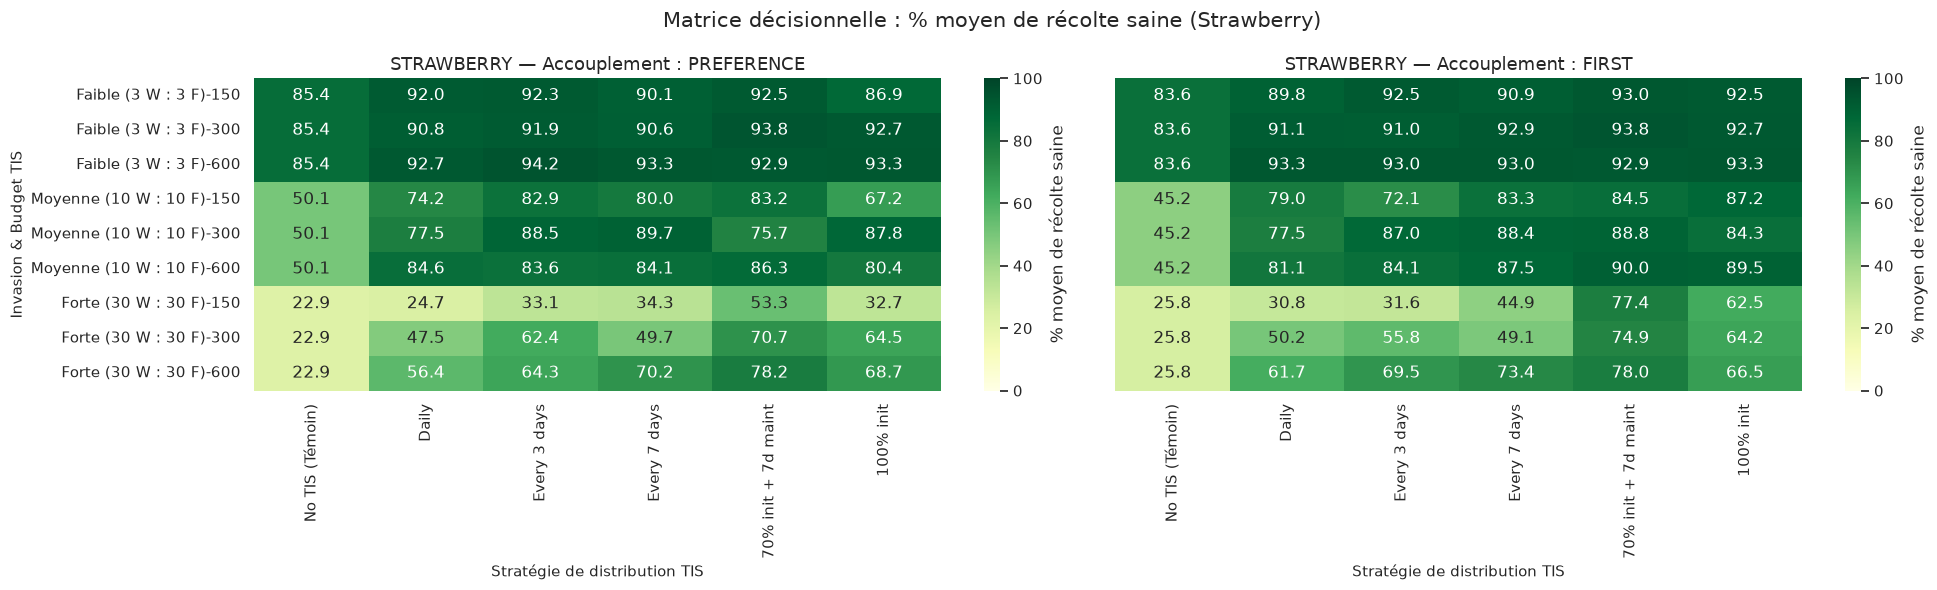

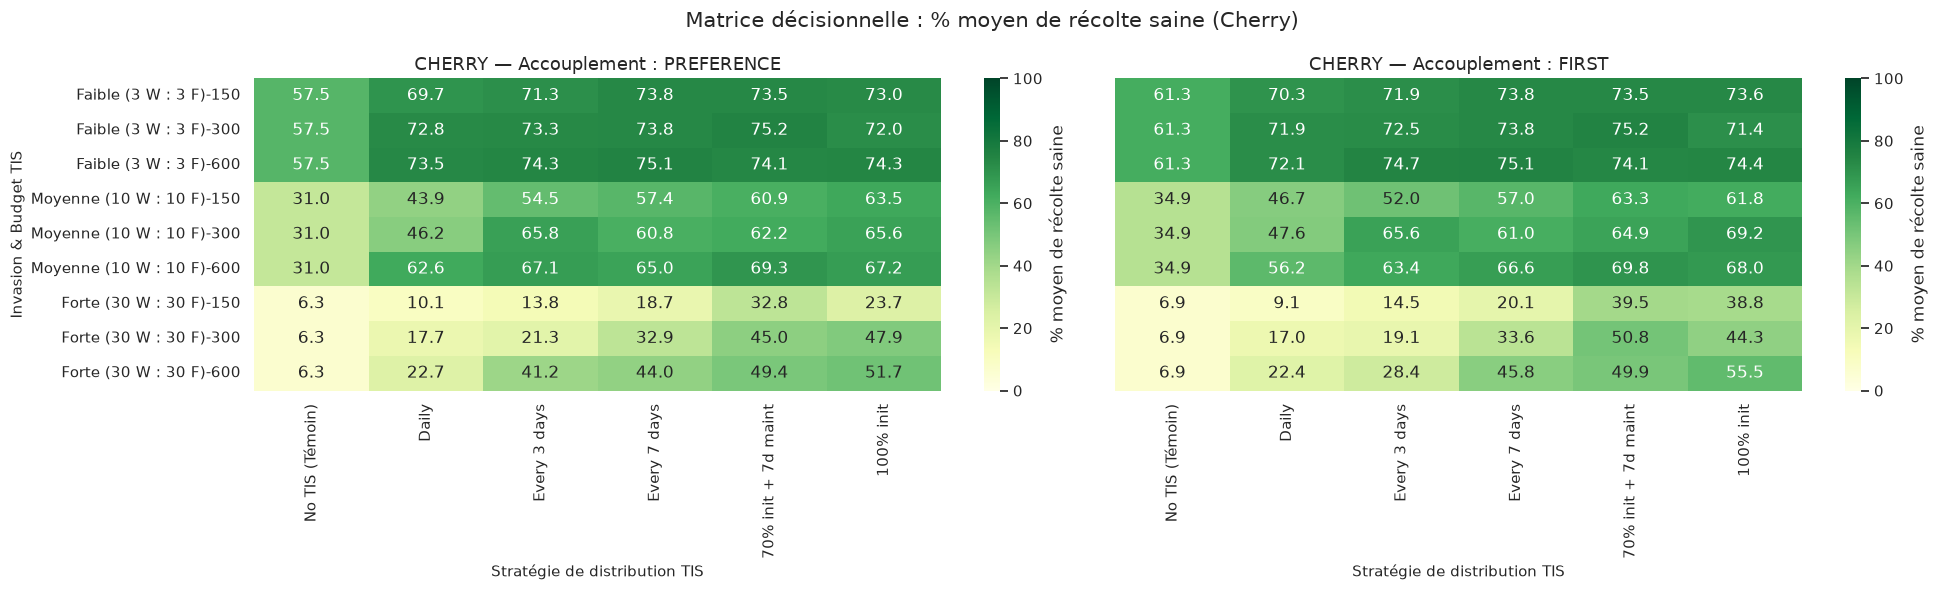

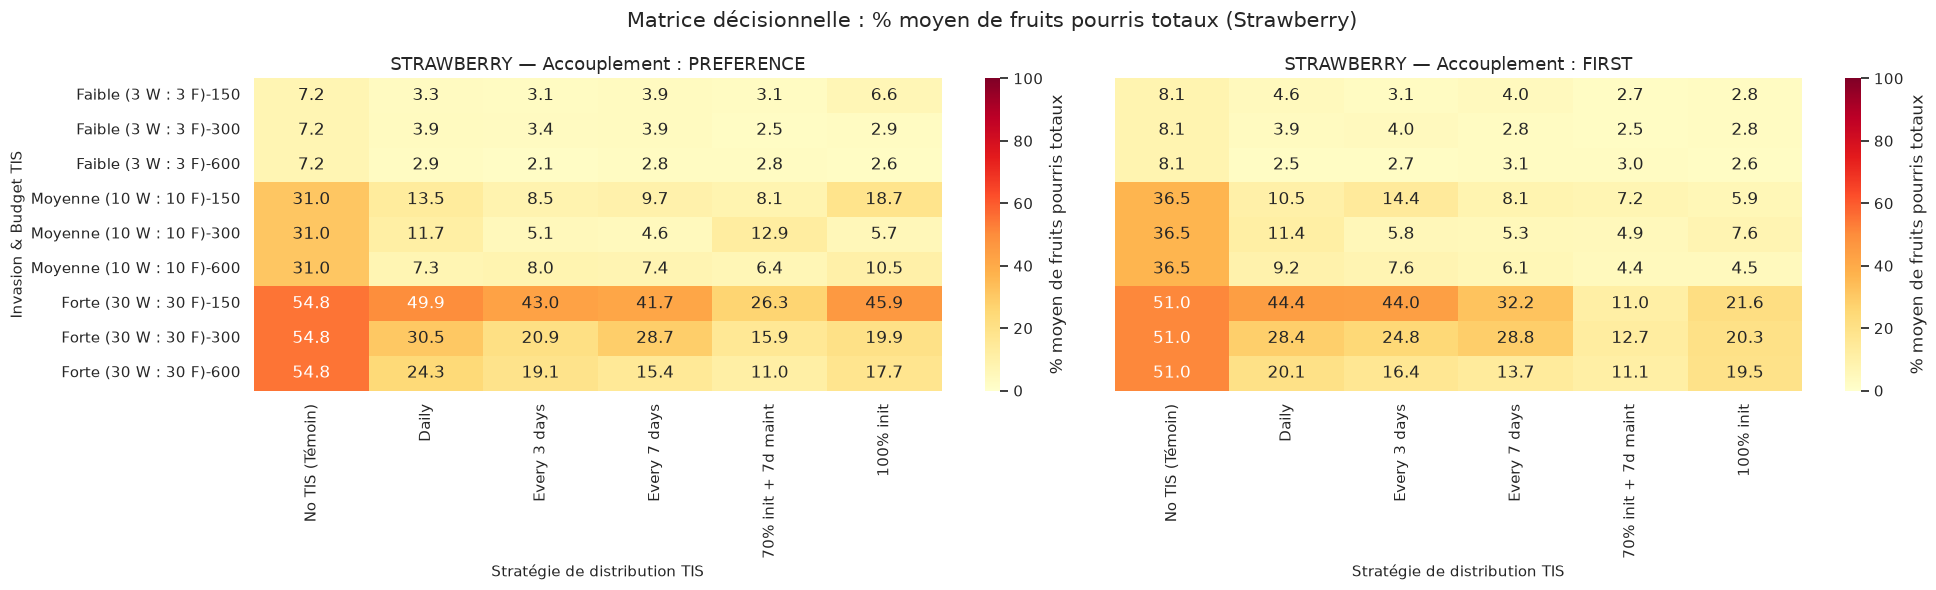

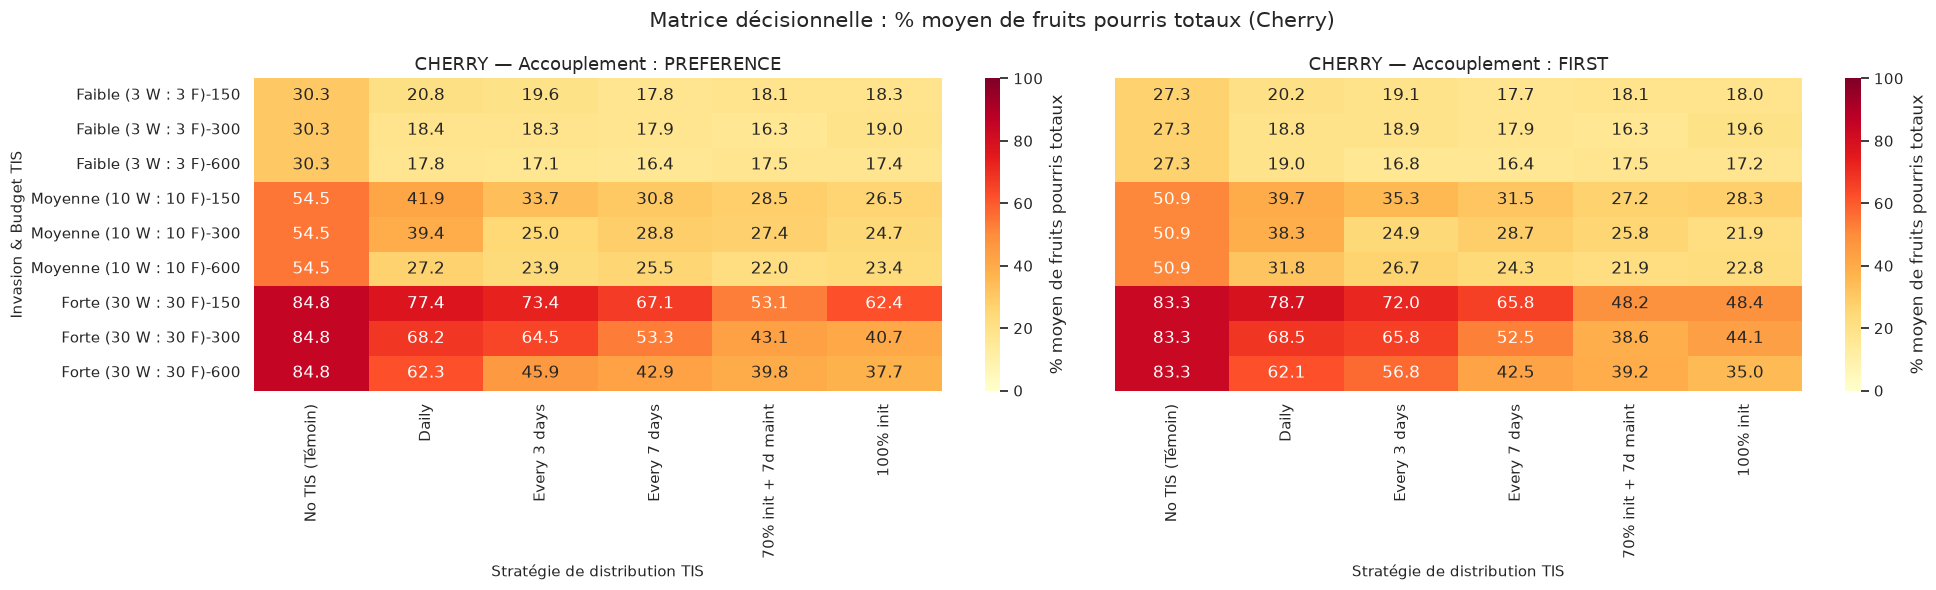

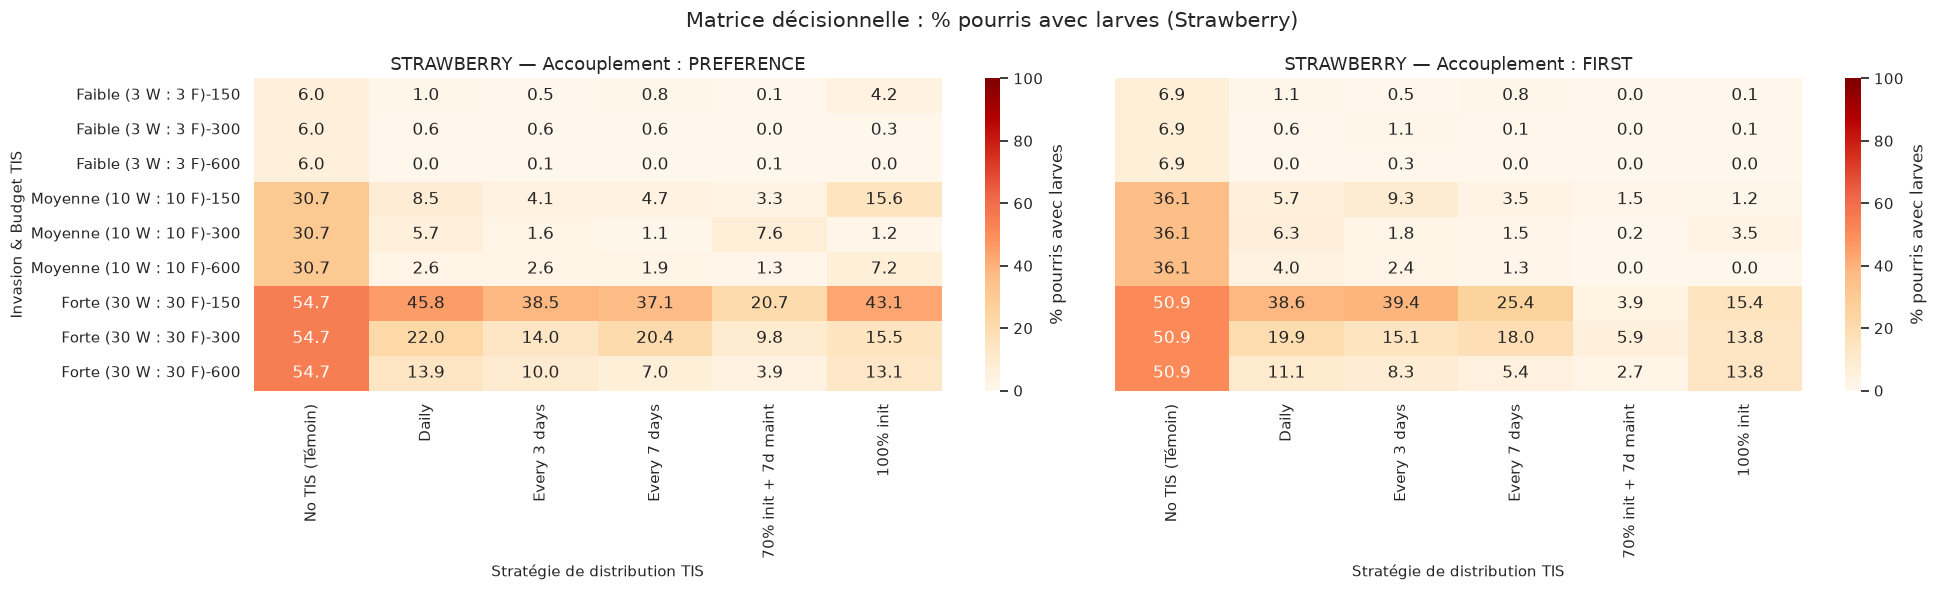

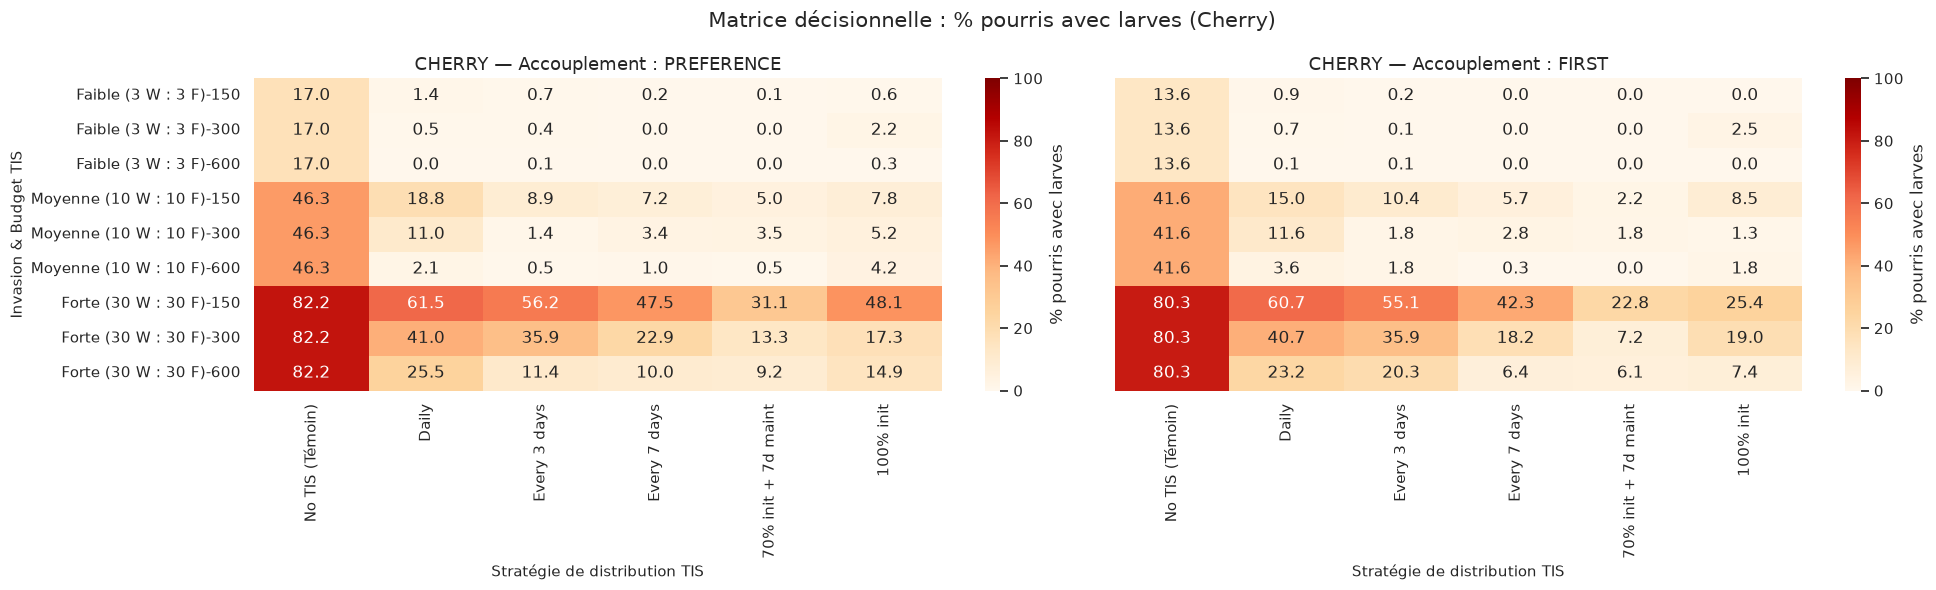

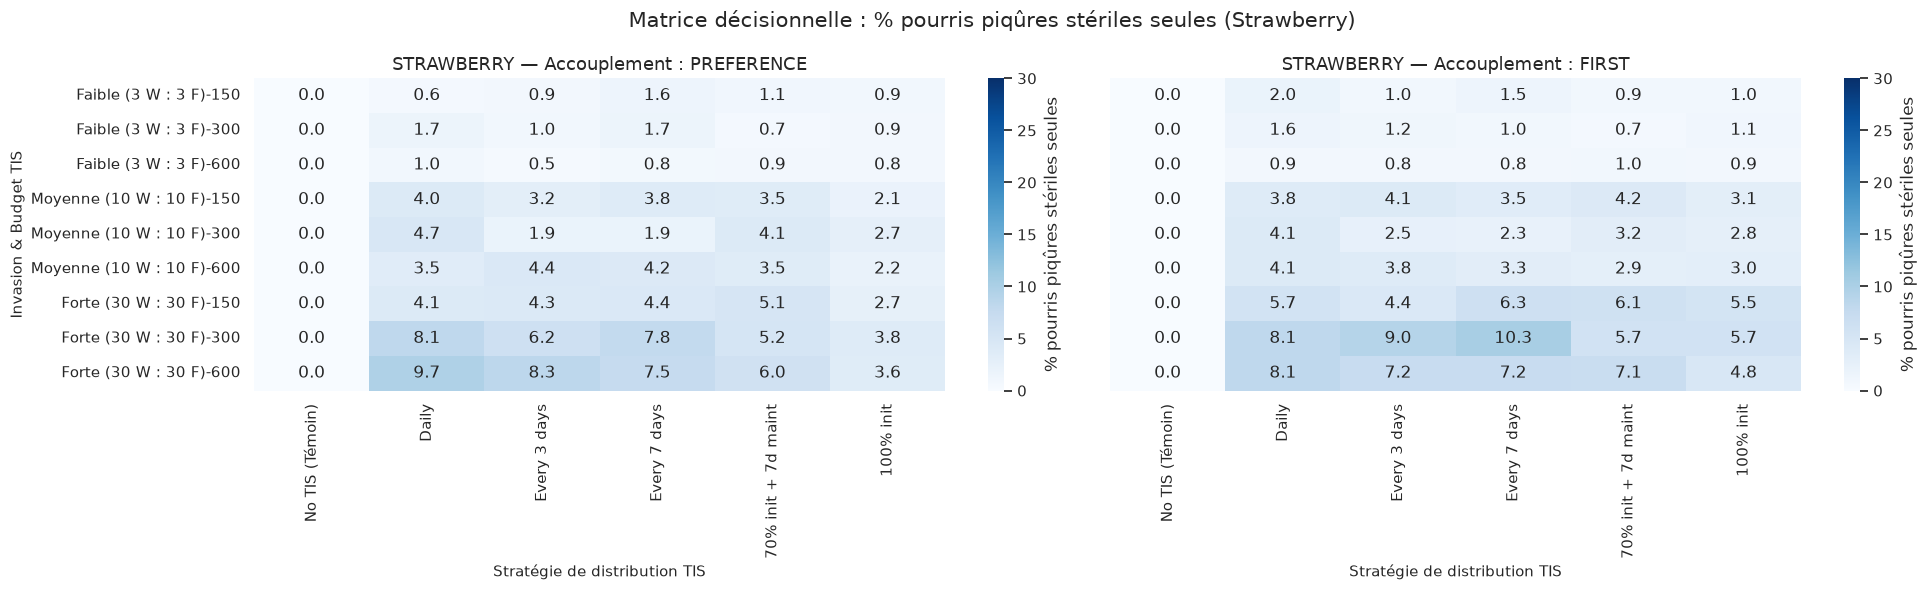

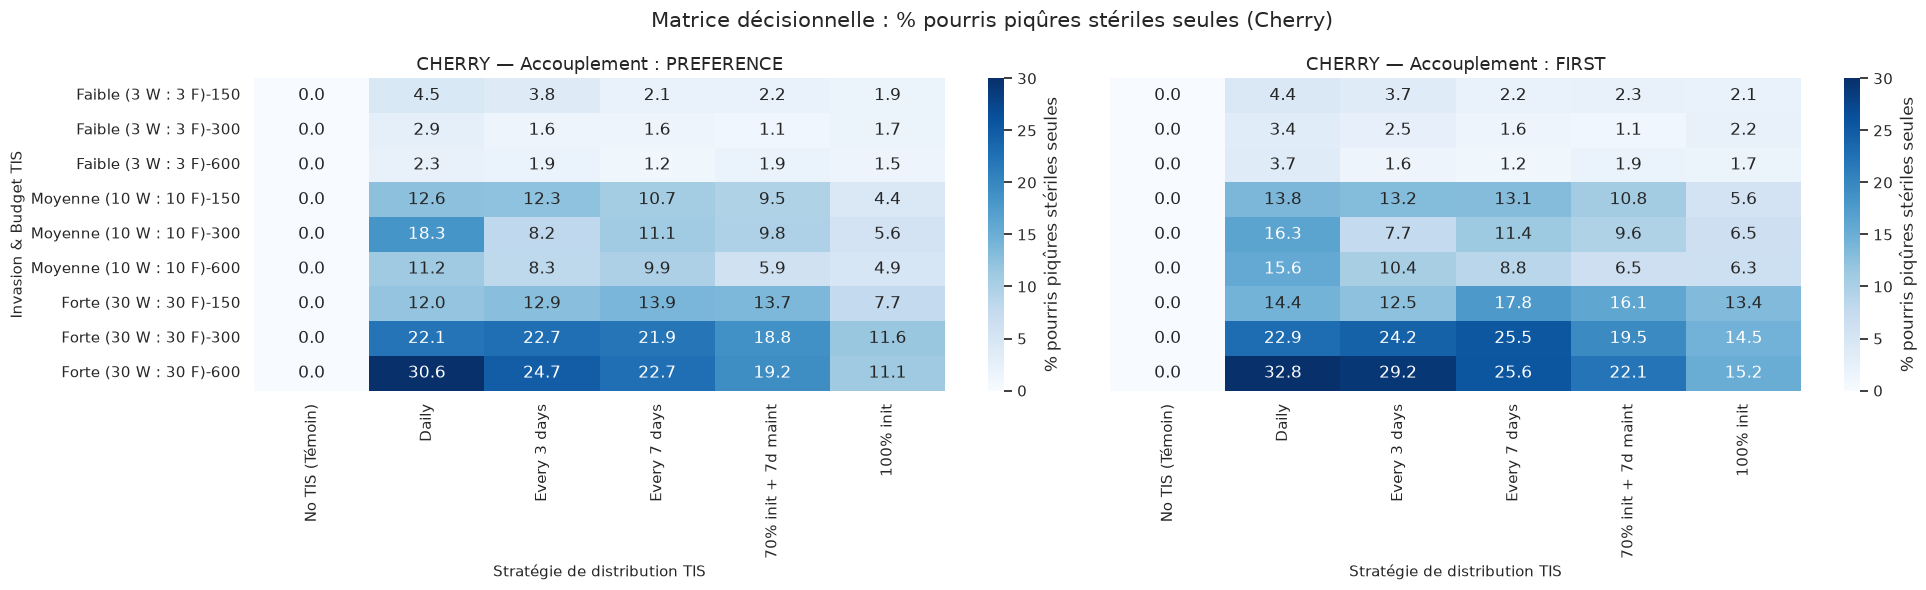

In [11]:
# 9. VISUALISATION 3 : MATRICES DÉCISIONNELLES (HEATMAPS AGRONOMIQUES)
invasion_order = ["Faible (3 W : 3 F)", "Moyenne (10 W : 10 F)", "Forte (30 W : 30 F)"]
budget_order = [150, 300, 600]
strategy_cols = ["Daily", "Every 3 days", "Every 7 days", "70% init + 7d maint", "100% init"]

heatmaps_to_plot = [
    ("Harvested - clean (%)", "% moyen de récolte saine", "YlGn", 0, 100),
    ("Rotten (%)", "% moyen de fruits pourris totaux", "YlOrRd", 0, 100),
    ("Rotten - larvae (%)", "% pourris avec larves", "OrRd", 0, 100),
    ("Rotten - sterile only (%)", "% pourris piqûres stériles seules", "Blues", 0, 30)
]

for metric_col, metric_label, colormap, v_min, v_max in heatmaps_to_plot:
    if metric_col not in exp_df.columns: continue
    for c_name in ["strawberry", "cherry"]:
        fig, axes = plt.subplots(1, 2, figsize=(20, 6), sharey=True)
        for idx, rem in enumerate(["preference", "first"]):
            sub_c = exp_df[(exp_df["Crop"] == c_name) & (exp_df["Remating"] == rem)]
            no_tis_baseline = sub_c[sub_c["Strategy"] == "No TIS"].groupby("Invasion")[metric_col].mean()
            
            sub_tis = sub_c[sub_c["Budget"] > 0]
            pivot = sub_tis.pivot_table(index=["Invasion", "Budget"], columns="Strategy", values=metric_col, aggfunc="mean")
            
            existing_cols = [c for c in strategy_cols if c in pivot.columns]
            pivot = pivot.reindex(columns=existing_cols)
            pivot.insert(0, "No TIS (Témoin)", [no_tis_baseline.get(inv, np.nan) for inv, b in pivot.index])
            
            idx_order = pd.MultiIndex.from_product([invasion_order, budget_order], names=["Invasion", "Budget"])
            pivot = pivot.reindex(index=idx_order).fillna(0.0)
            
            sns.heatmap(pivot, annot=True, fmt=".1f", cmap=colormap, ax=axes[idx], vmin=v_min, vmax=v_max, cbar_kws={'label': metric_label})
            axes[idx].set_title(f"{c_name.upper()} — Accouplement : {rem.upper()}", fontsize=13)
            axes[idx].set_xlabel("Stratégie de distribution TIS", fontsize=11)
            if idx == 0: axes[idx].set_ylabel("Invasion & Budget TIS", fontsize=11)
            else: axes[idx].set_ylabel("")
            
        plt.suptitle(f"Matrice décisionnelle : {metric_label} ({c_name.capitalize()})", fontsize=15, y=0.98)
        plt.tight_layout()
        plt.show()

Simulation Fraise en cours...
Simulation Cerise en cours...


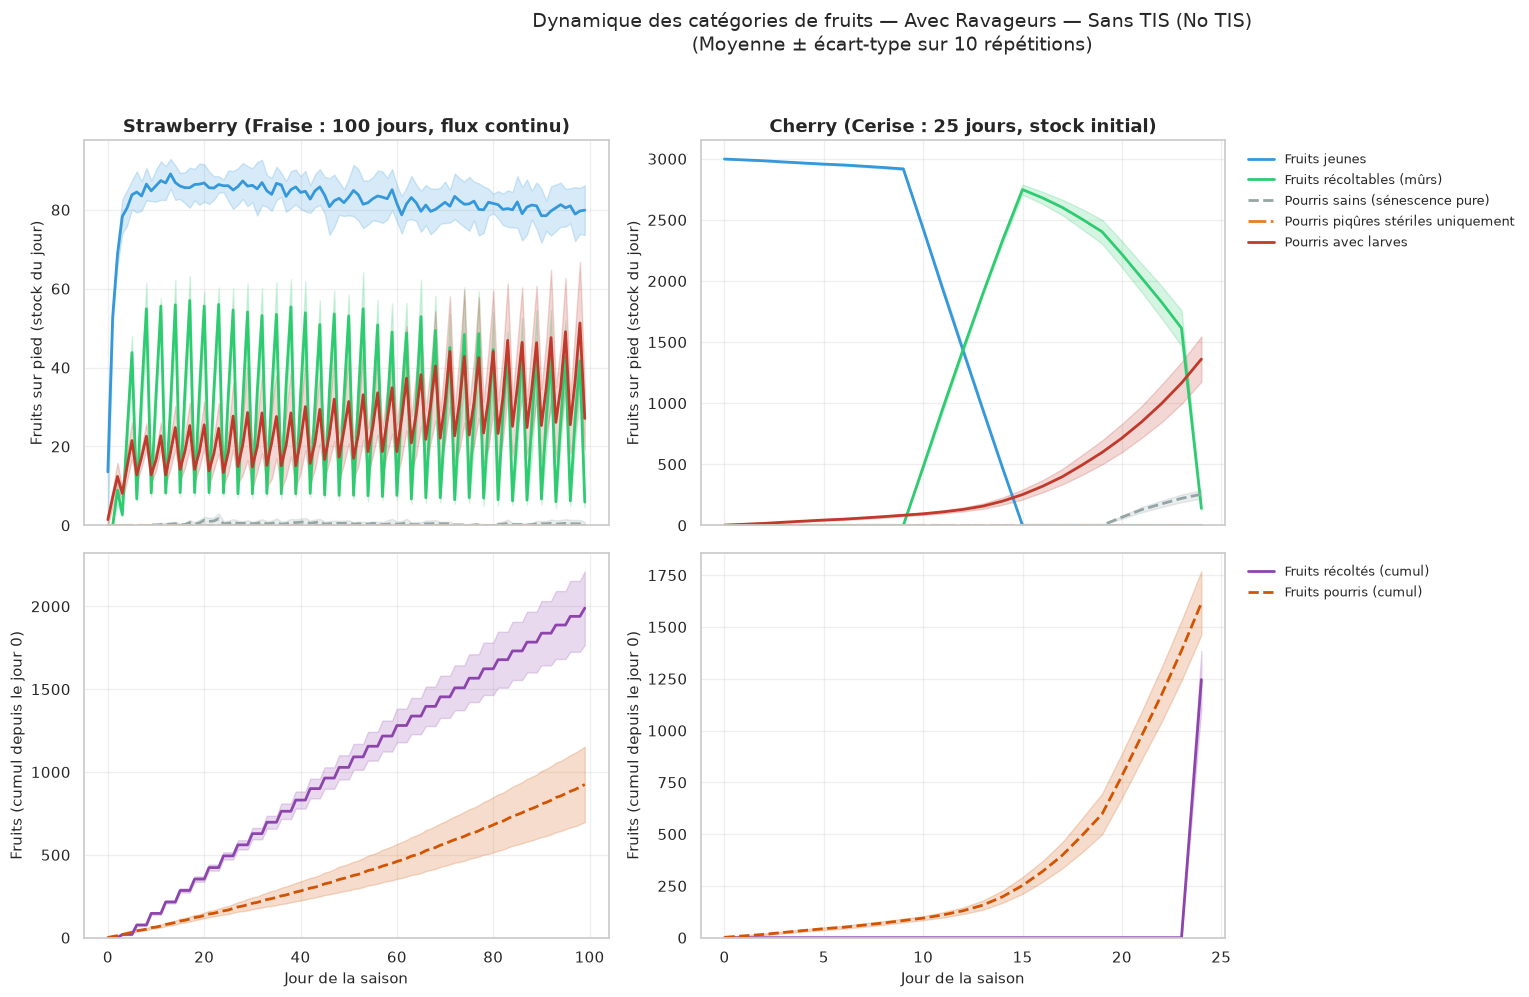

In [12]:
# ============================================================
# DYNAMIQUE COMPLÈTE DES FRUITS DÉCOMPOSÉS AU COURS DU TEMPS
# ============================================================

def run_fruit_dynamics_simulation(
    crop_params, 
    num_wild=10, 
    num_females=10, 
    sterile_sched=None, 
    remating="preference",
    n_reps=10, 
    base_seed=42
):
    """
    Simule n_reps fois l'évolution détaillée de chaque statut de fruit.
    Pour un témoin sans ravageur : passer num_wild=0, num_females=0.
    """
    all_dfs = []
    for rep in range(n_reps):
        model = RematingModel(
            crop_parameters=crop_params,
            sterile_release_schedule=sterile_sched if sterile_sched else {},
            num_agents_wild=num_wild,
            num_agents_females=num_females,
            num_agents_sterile=0,
            num_agents_larvae=0,
            sperm_selection=remating,
            rotten_puncture_probability=0.10,
            seed=base_seed + rep * 100
        )
        for _ in range(crop_params.season_length):
            model.advance_day()
            
        df = model.get_model_dataframe()
        df["Crop"] = crop_params.name
        df["Replicate"] = rep
        all_dfs.append(df)
        
    return pd.concat(all_dfs, ignore_index=True)


# ------------------------------------------------------------
# 1. LANCEMENT DES SIMULATIONS
# ------------------------------------------------------------
# Choisissez le scénario à visualiser (ex: "No TIS", "Daily", ou "Sans ravageur")
SCENARIO_NAME = "Avec Ravageurs — Sans TIS (No TIS)"
# Pour tester "Sans ravageurs", mettez num_wild=0, num_females=0

print("Simulation Fraise en cours...")
df_straw = run_fruit_dynamics_simulation(
    STRAWBERRY, 
    num_wild=10, 
    num_females=10, 
    sterile_sched={},  # No TIS (ou calendrier TIS de votre choix)
    n_reps=10, 
    base_seed=101
)

print("Simulation Cerise en cours...")
df_cherry = run_fruit_dynamics_simulation(
    CHERRY, 
    num_wild=10, 
    num_females=10, 
    sterile_sched={}, 
    n_reps=10, 
    base_seed=202
)


# ------------------------------------------------------------
# 2. VISUALISATION DES DYNAMIQUES DE FRUITS
# ------------------------------------------------------------
# Lisibilité : avant, tout était sur UN seul axe bloqué à 3100 parce que le cumul
# des récoltes monte à 2000-3000. Du coup les stocks journaliers (quelques dizaines
# de fruits sur pied) étaient écrasés en une bande plate en bas, et la légende
# tombait sur les courbes. Je sépare en deux lignes : en haut les stocks du jour
# avec leur propre échelle, en bas les cumuls. Légende sortie du graphe.
fig, axes = plt.subplots(2, 2, figsize=(18, 10), sharex="col")

daily_categories = [
    ("Young_fruits", "Fruits jeunes", "#3498db", "-"),
    ("Harvestable_fruits", "Fruits récoltables (mûrs)", "#2ecc71", "-"),
    ("Rotten_natural", "Pourris sains (sénescence pure)", "#95a5a6", "--"),
    ("Rotten_sterile_only", "Pourris piqûres stériles uniquement", "#e67e22", "-."),
    ("Rotten_larvae", "Pourris avec larves", "#c0392b", "-"),
]
cumulative_categories = [
    ("Harvested_cumul", "Fruits récoltés (cumul)", "#8e44ad", "-"),
    ("Rotten_cumul", "Fruits pourris (cumul)", "#d35400", "--"),
]

for idx, (crop_name, c_df) in enumerate(zip(["strawberry", "cherry"], [df_straw, df_cherry])):
    ax_top, ax_bot = axes[0, idx], axes[1, idx]

    for col_name, label_name, color, style in daily_categories:
        if col_name in c_df.columns:
            sns.lineplot(data=c_df, x="Time", y=col_name, label=label_name, color=color,
                         linestyle=style, linewidth=2.0, ax=ax_top, errorbar="sd")
    for col_name, label_name, color, style in cumulative_categories:
        if col_name in c_df.columns:
            sns.lineplot(data=c_df, x="Time", y=col_name, label=label_name, color=color,
                         linestyle=style, linewidth=2.0, ax=ax_bot, errorbar="sd")

    title_suffix = "(Fraise : 100 jours, flux continu)" if crop_name == "strawberry" else "(Cerise : 25 jours, stock initial)"
    ax_top.set_title(f"{crop_name.capitalize()} {title_suffix}", fontsize=13, fontweight="bold")
    ax_top.set_ylabel("Fruits sur pied (stock du jour)", fontsize=11)
    ax_bot.set_ylabel("Fruits (cumul depuis le jour 0)", fontsize=11)
    ax_bot.set_xlabel("Jour de la saison", fontsize=11)
    for ax in (ax_top, ax_bot):
        ax.grid(True, alpha=0.3)
        ax.set_ylim(bottom=0)
        ax.margins(y=0.08)
        if idx == 1:
            ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=9.5, frameon=False)
        elif ax.get_legend():
            ax.get_legend().remove()

plt.suptitle(f"Dynamique des catégories de fruits — {SCENARIO_NAME}\n(Moyenne ± écart-type sur 10 répétitions)", fontsize=14, y=0.995)
plt.tight_layout(rect=(0, 0, 0.86, 0.97))
plt.show()


Chargement instantané des données depuis 'dynamiques_temporelles_journalieres.csv'...


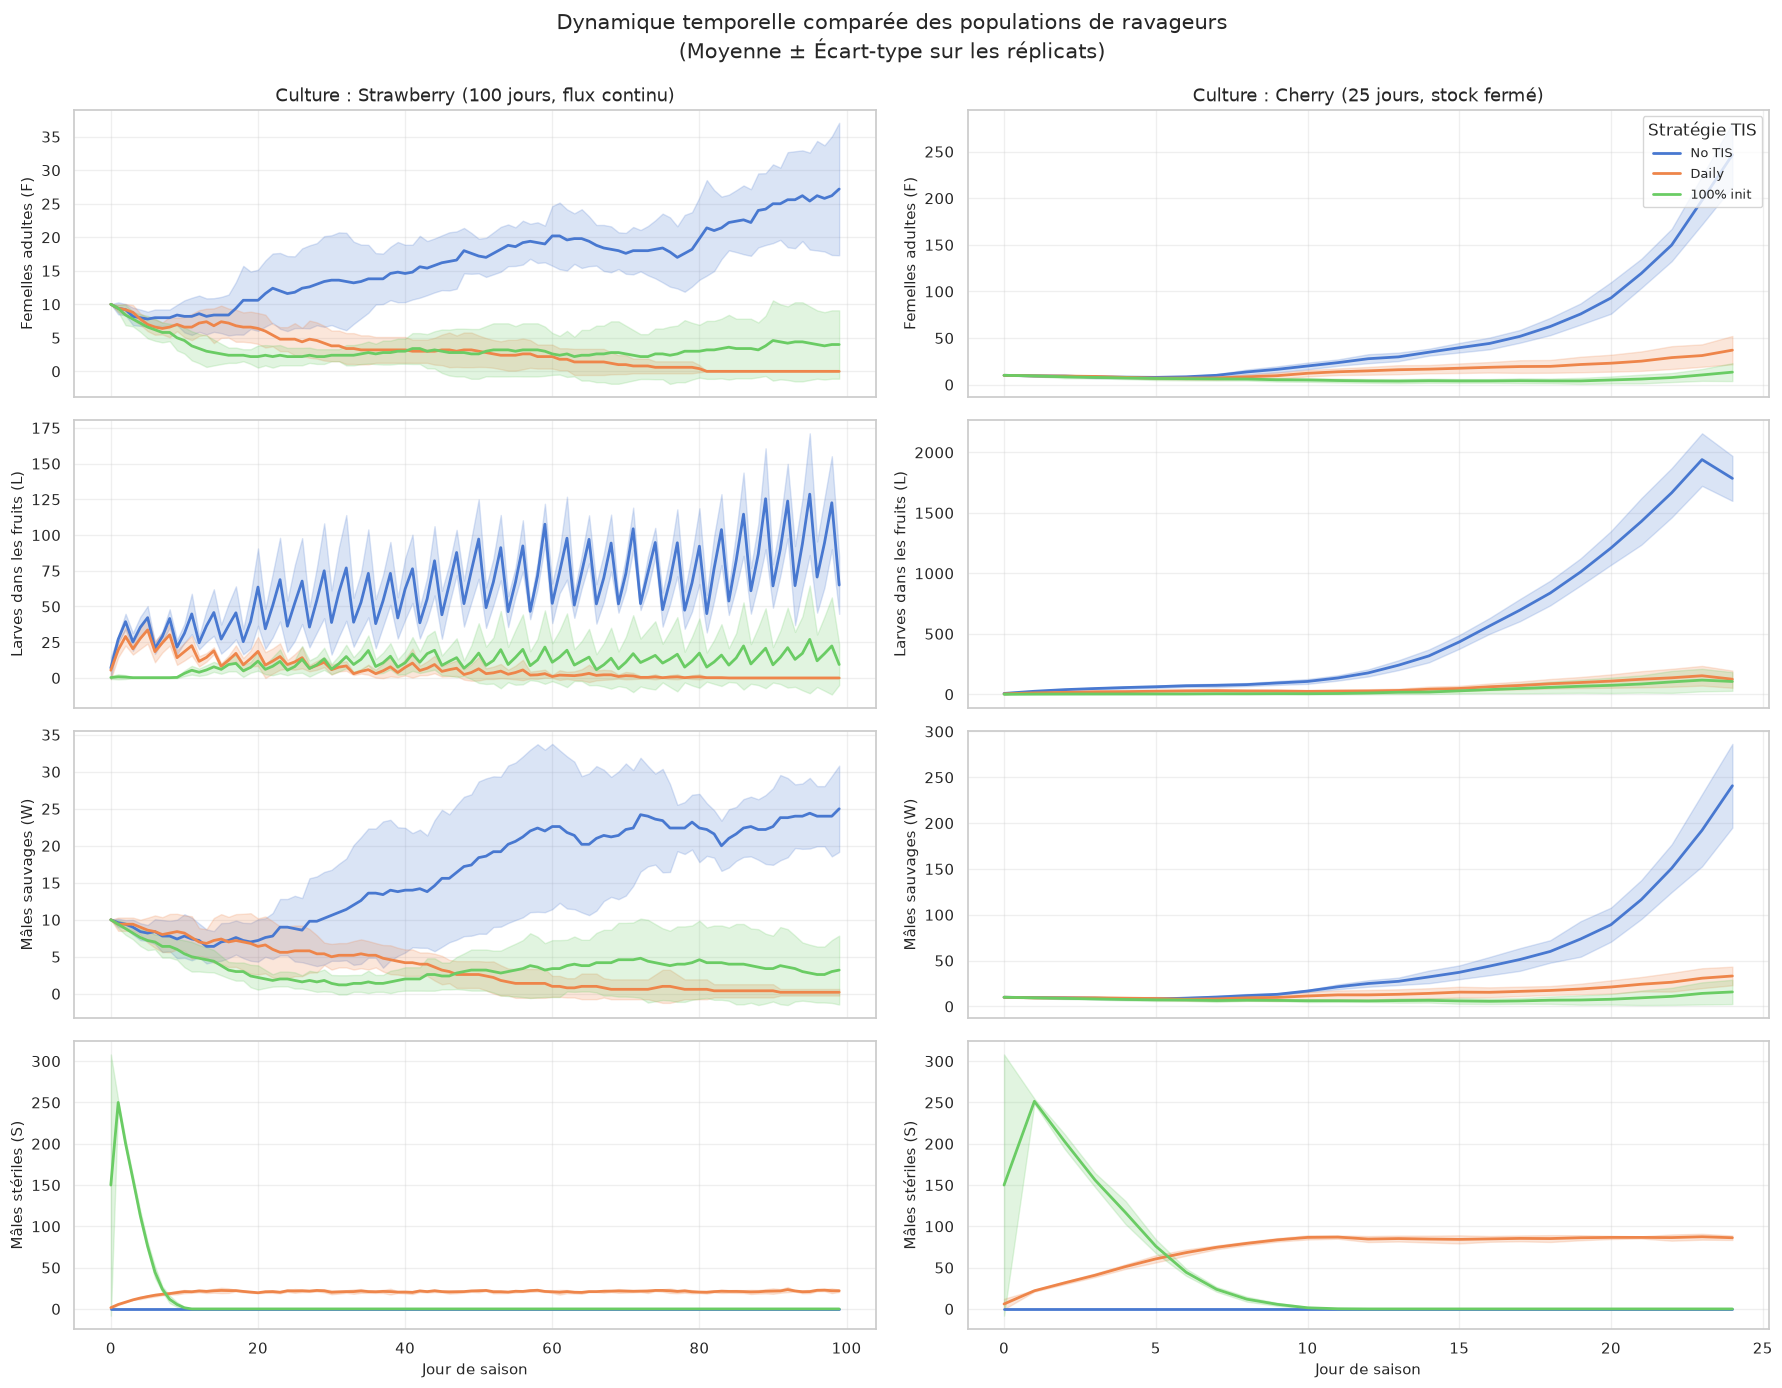

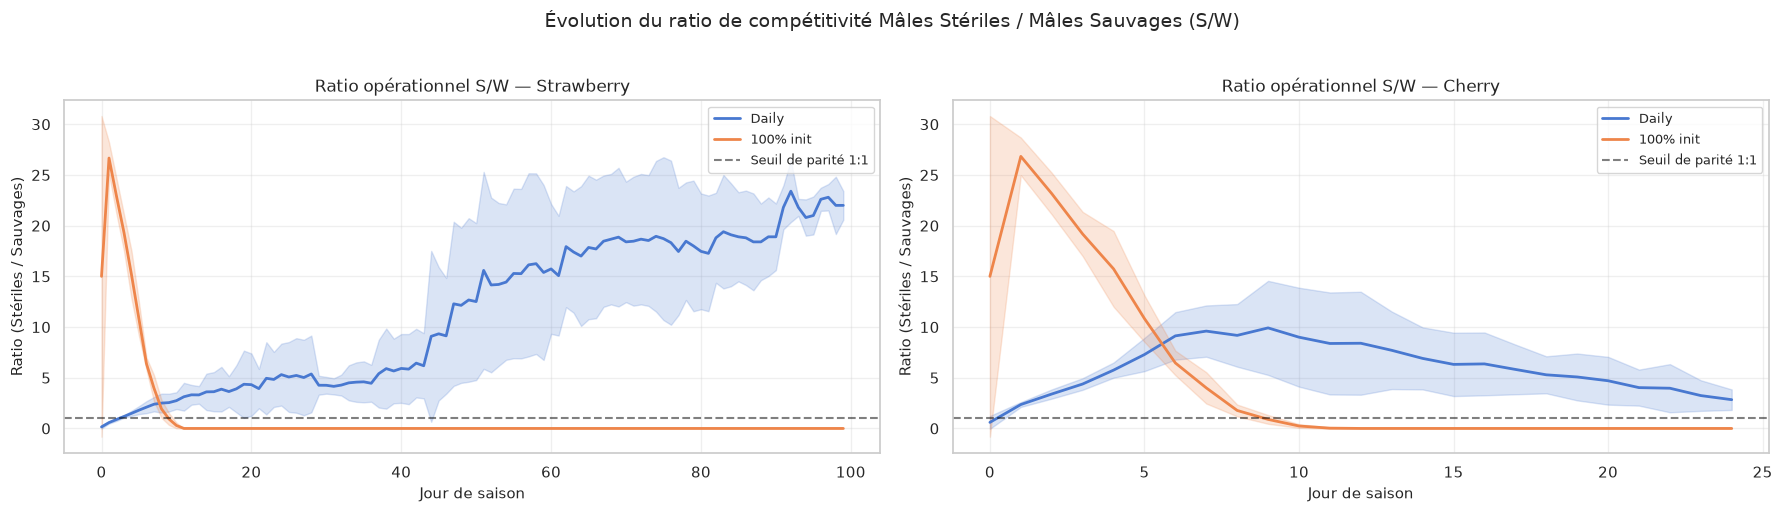

In [13]:
# ============================================================
# GÉNÉRATION DU FICHIER ET TRACÉ DES DYNAMIQUES DES POPULATIONS
# ============================================================
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

DYN_CSV_FILE = "dynamiques_temporelles_journalieres.csv"
FORCE_RERUN_DYN = False

# 1. Vérification du cache : s'il n'existe pas, on lance les simulations ciblées
if not os.path.exists(DYN_CSV_FILE) or FORCE_RERUN_DYN:
    print(f"Génération du fichier '{DYN_CSV_FILE}' en cours...")
    
    strats_to_track = ["No TIS", "Daily", "100% init"]
    budget_test = 300
    n_reps_dyn = 5  # 5 répétitions suffisent pour afficher les moyennes ± écarts-types
    
    records_dyn = []
    
    for crop in [STRAWBERRY, CHERRY]:
        strats_sched = make_strategies(budget_test, crop.season_length)
        for s_name in strats_to_track:
            sched = {} if s_name == "No TIS" else strats_sched.get(s_name, {})
            b_val = 0 if s_name == "No TIS" else budget_test
            
            for rem in ["preference", "first"]:
                for rep in range(n_reps_dyn):
                    seed = 42 + rep * 1000 + len(s_name) * 17
                    model = RematingModel(
                        crop_parameters=crop,
                        sterile_release_schedule=sched,
                        num_agents_wild=10,
                        num_agents_females=10,
                        sperm_selection=rem,
                        rotten_puncture_probability=0.10,
                        seed=seed
                    )
                    for _ in range(crop.season_length):
                        model.advance_day()
                        
                    d = model.get_model_dataframe()
                    d["Crop"] = crop.name
                    d["Strategy"] = s_name
                    d["Budget"] = b_val
                    d["Remating"] = rem
                    d["Replicate"] = rep
                    records_dyn.append(d)
                    
    dyn_plot_df = pd.concat(records_dyn, ignore_index=True)
    dyn_plot_df.to_csv(DYN_CSV_FILE, index=False)
    print(f"Fichier '{DYN_CSV_FILE}' créé et sauvegardé avec succès.")
else:
    print(f"Chargement instantané des données depuis '{DYN_CSV_FILE}'...")
    dyn_plot_df = pd.read_csv(DYN_CSV_FILE)

# 2. Préparation des données pour les graphiques
strats_to_display = ["No TIS", "Daily", "100% init"]
sub_pop = dyn_plot_df[
    (dyn_plot_df["Strategy"].isin(strats_to_display)) &
    (dyn_plot_df["Remating"] == "preference")
]

crops = ["strawberry", "cherry"]
pop_variables = [
    ("Females", "Femelles adultes (F)", "#e74c3c"),
    ("Larvae", "Larves dans les fruits (L)", "#8e44ad"),
    ("Wild_males", "Mâles sauvages (W)", "#2c3e50"),
    ("Sterile_males", "Mâles stériles (S)", "#2980b9")
]

# 3. Tracé des 4 populations (Femelles, Larves, Mâles W, Mâles S)
fig, axes = plt.subplots(len(pop_variables), 2, figsize=(18, 14), sharex="col")

for c_idx, c_name in enumerate(crops):
    c_df = sub_pop[sub_pop["Crop"] == c_name]
    
    for v_idx, (var_name, var_label, col) in enumerate(pop_variables):
        ax = axes[v_idx, c_idx]
        
        sns.lineplot(
            data=c_df,
            x="Time",
            y=var_name,
            hue="Strategy",
            ax=ax,
            errorbar="sd",
            linewidth=2.0
        )
        
        ax.set_ylabel(var_label, fontsize=11)
        ax.grid(True, alpha=0.3)
        
        if v_idx == 0:
            title_suffix = "(100 jours, flux continu)" if c_name == "strawberry" else "(25 jours, stock fermé)"
            ax.set_title(f"Culture : {c_name.capitalize()} {title_suffix}", fontsize=13)
            
        if v_idx == 0 and c_idx == 1:
            ax.legend(title="Stratégie TIS", loc="upper right", fontsize=9.5)
        else:
            if ax.get_legend():
                ax.get_legend().remove()

axes[len(pop_variables) - 1, 0].set_xlabel("Jour de saison", fontsize=11)
axes[len(pop_variables) - 1, 1].set_xlabel("Jour de saison", fontsize=11)

plt.suptitle(
    "Dynamique temporelle comparée des populations de ravageurs\n(Moyenne ± Écart-type sur les réplicats)",
    fontsize=15,
    y=0.99
)
plt.tight_layout()
plt.show()

# 4. Tracé du Ratio de compétitivité S/W
sub_ratio = sub_pop[sub_pop["Strategy"] != "No TIS"].copy()

if "SW_Ratio" not in sub_ratio.columns:
    sub_ratio["SW_Ratio"] = sub_ratio["Sterile_males"] / np.maximum(1, sub_ratio["Wild_males"])

fig, axes = plt.subplots(1, 2, figsize=(18, 5), sharey=False)

for c_idx, c_name in enumerate(crops):
    ax = axes[c_idx]
    c_df = sub_ratio[sub_ratio["Crop"] == c_name]
    
    sns.lineplot(
        data=c_df,
        x="Time",
        y="SW_Ratio",
        hue="Strategy",
        ax=ax,
        errorbar="sd",
        linewidth=2.0
    )
    
    ax.set_title(f"Ratio opérationnel S/W — {c_name.capitalize()}", fontsize=12)
    ax.set_xlabel("Jour de saison", fontsize=11)
    ax.set_ylabel("Ratio (Stériles / Sauvages)", fontsize=11)
    ax.grid(True, alpha=0.3)
    ax.axhline(1.0, color="black", linestyle="--", alpha=0.5, label="Seuil de parité 1:1")
    ax.legend(loc="upper right", fontsize=9.5)

plt.suptitle("Évolution du ratio de compétitivité Mâles Stériles / Mâles Sauvages (S/W)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## 📊 Analyse Cinétique et Dynamique Temporelle (Insectes & Fruits)
Cette section exploite les trajectoires journalières enregistrées (`dynamiques_temporelles_journalieres.csv`) pour analyser la cinétique des populations de ravageurs et l'état des fruits au fil de la saison. 

L'objectif est de comprendre **comment le timing des lâchers TIS (fréquence et budget)** interagit avec la phénologie des deux cultures :
1. **Fraise** (100 jours, production continue et récoltes échelonnées).
2. **Cerise** (25 jours, stock initial fermé et fenêtre unique de maturation).

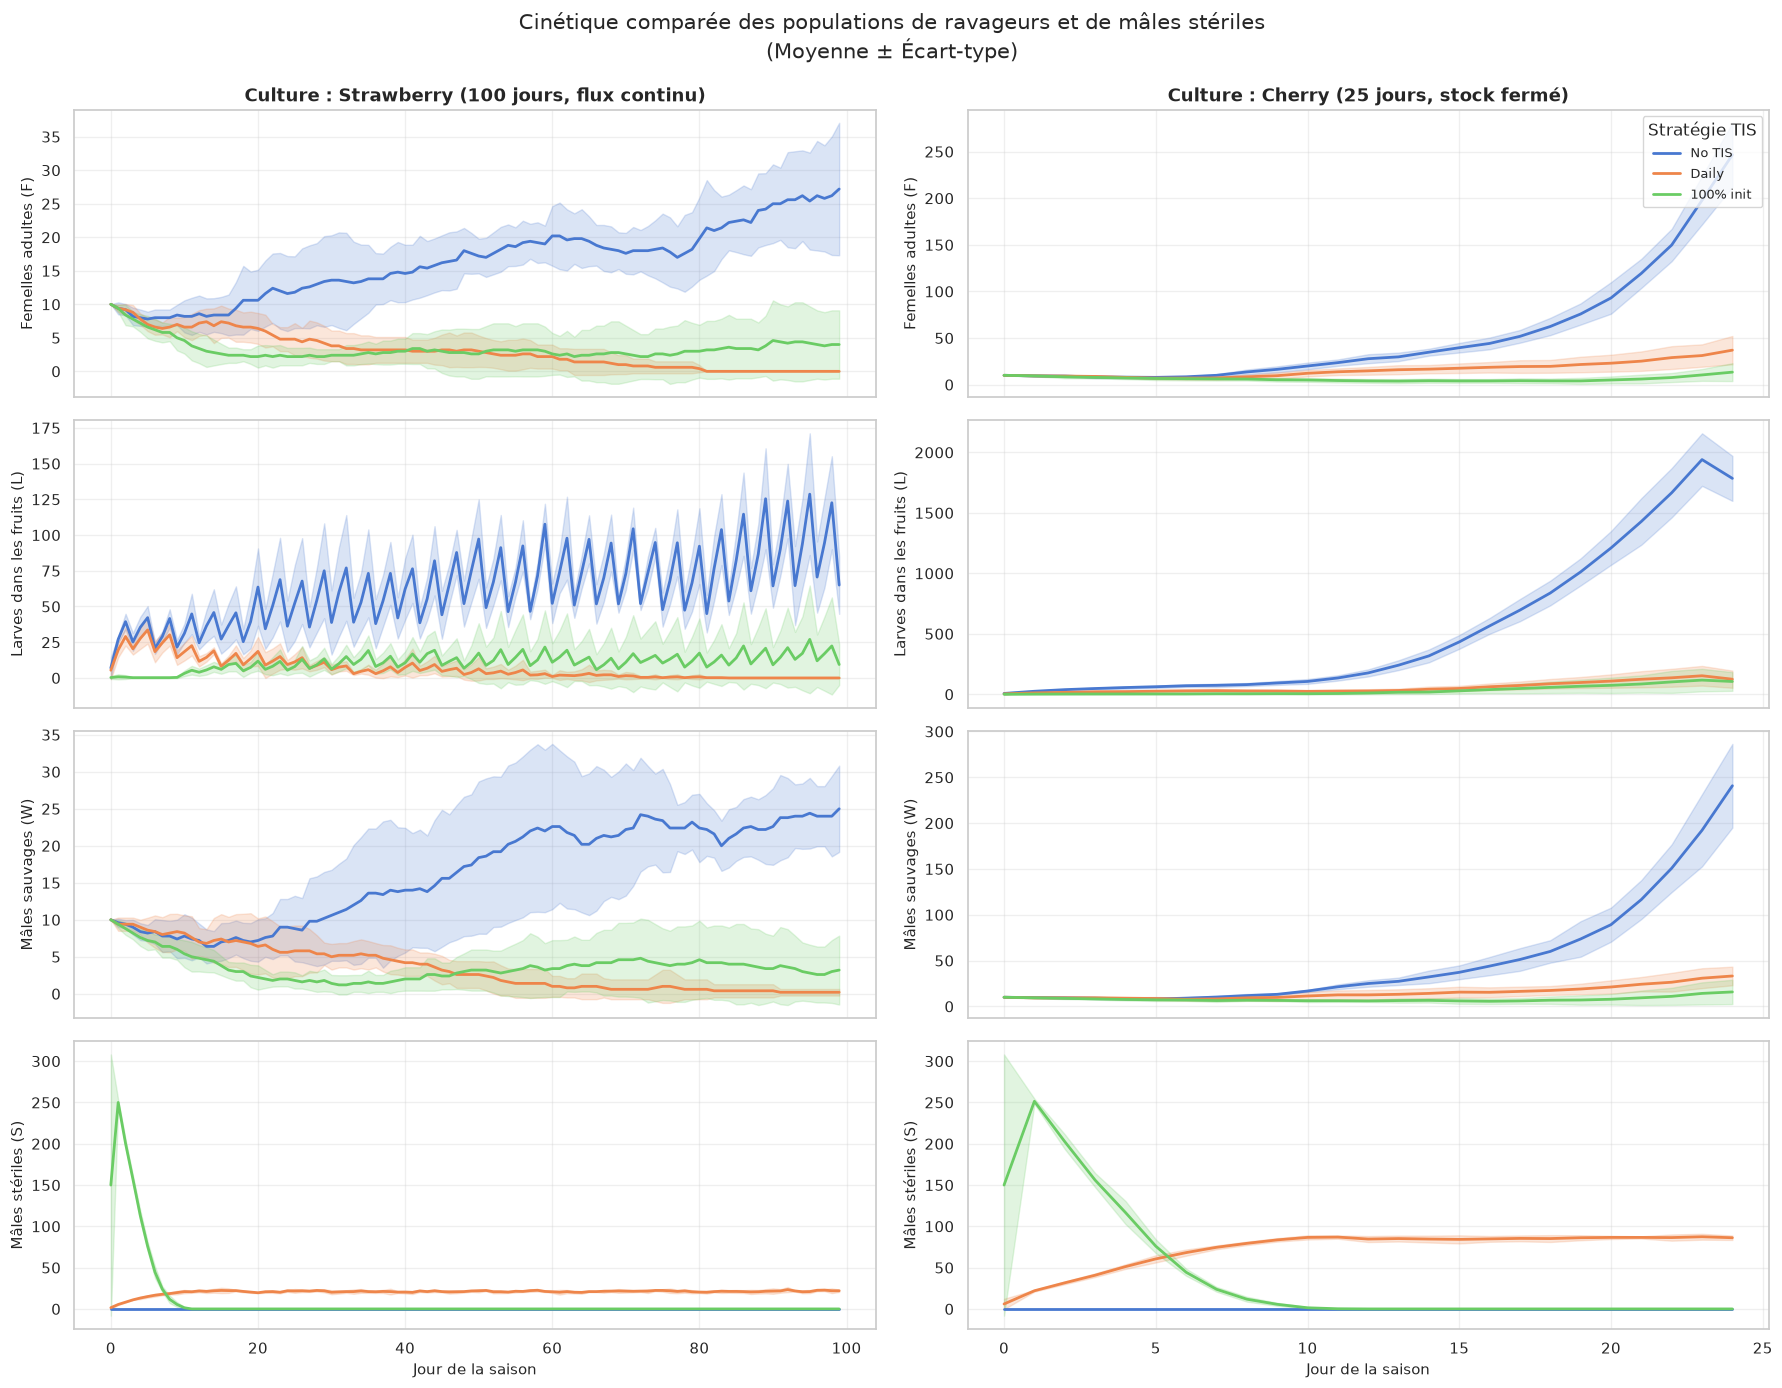

In [14]:
# ============================================================
# VISUALISATION TEMPORELLE : POPULATIONS D'INSECTES
# ============================================================
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Chargement des données temporelles pré-calculées
dyn_df = pd.read_csv("dynamiques_temporelles_journalieres.csv")

# Sélection d'un scénario de référence (ex: Invasion Moyenne, régime d'accouplement 'preference')
strat_focus = ["No TIS", "Daily", "100% init"]
sub_pop = dyn_df[
    (dyn_df["Strategy"].isin(strat_focus)) & 
    (dyn_df["Remating"] == "preference")
]

# 2. Configuration du graphique des populations d'insectes
pop_vars = [
    ("Females", "Femelles adultes (F)", "#e74c3c"),
    ("Larvae", "Larves dans les fruits (L)", "#8e44ad"),
    ("Wild_males", "Mâles sauvages (W)", "#2c3e50"),
    ("Sterile_males", "Mâles stériles (S)", "#2980b9")
]

fig, axes = plt.subplots(len(pop_vars), 2, figsize=(18, 14), sharex="col")
crops = ["strawberry", "cherry"]

for c_idx, c_name in enumerate(crops):
    c_df = sub_pop[sub_pop["Crop"] == c_name]
    
    for v_idx, (var_name, var_label, col) in enumerate(pop_vars):
        ax = axes[v_idx, c_idx]
        
        sns.lineplot(
            data=c_df,
            x="Time",
            y=var_name,
            hue="Strategy",
            ax=ax,
            errorbar="sd",
            linewidth=2.0
        )
        
        ax.set_ylabel(var_label, fontsize=11)
        ax.grid(True, alpha=0.3)
        
        if v_idx == 0:
            suffix = "(100 jours, flux continu)" if c_name == "strawberry" else "(25 jours, stock fermé)"
            ax.set_title(f"Culture : {c_name.capitalize()} {suffix}", fontsize=13, fontweight='bold')
            
        if v_idx == 0 and c_idx == 1:
            ax.legend(title="Stratégie TIS", loc="upper right", fontsize=9.5)
        else:
            if ax.get_legend(): ax.get_legend().remove()

axes[-1, 0].set_xlabel("Jour de la saison", fontsize=11)
axes[-1, 1].set_xlabel("Jour de la saison", fontsize=11)

plt.suptitle("Cinétique comparée des populations de ravageurs et de mâles stériles\n(Moyenne ± Écart-type)", fontsize=15, y=0.99)
plt.tight_layout()
plt.show()

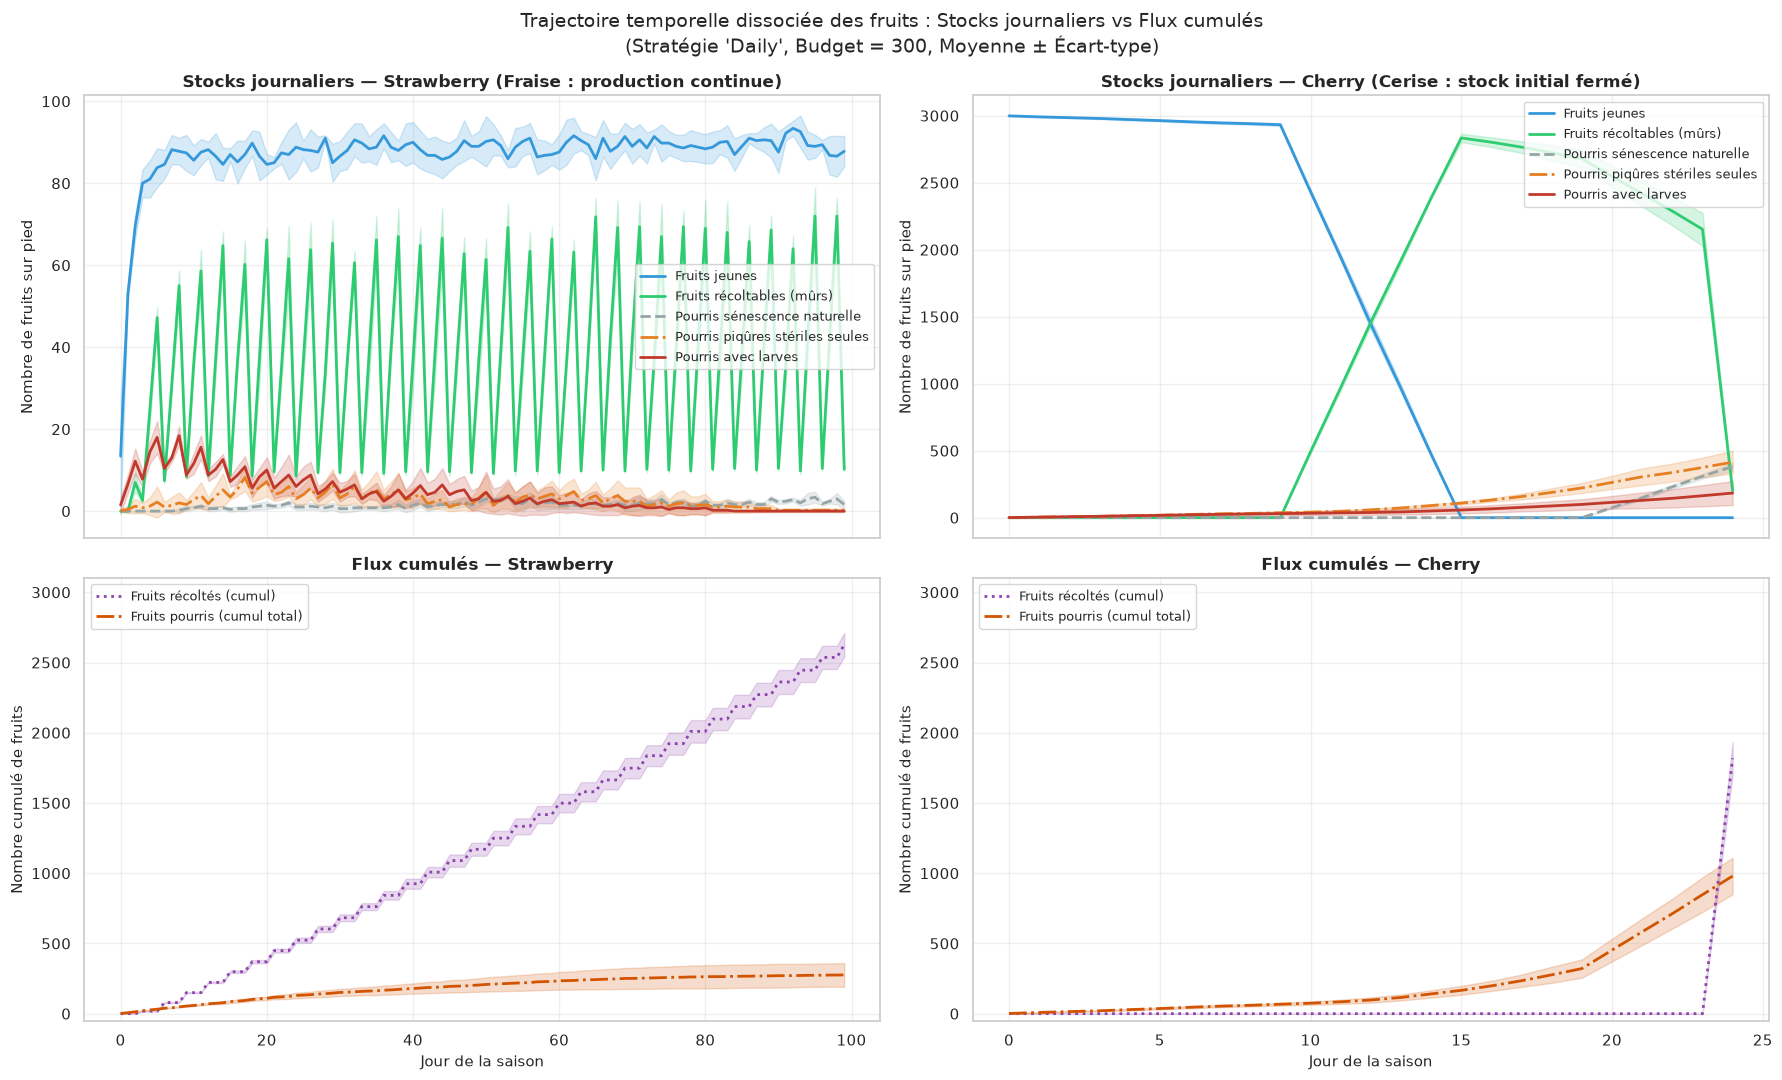

In [15]:
# ============================================================
# VISUALISATION TEMPORELLE : DYNAMIQUE COMPLÈTE DES FRUITS (ÉCHELLES SÉPARÉES)
# ============================================================

# Filtrage sur la stratégie 'Daily' à titre d'exemple comparatif
sub_fruits = dyn_df[
    (dyn_df["Strategy"] == "Daily") & 
    (dyn_df["Remating"] == "preference")
]

# On crée une figure avec 2 lignes (Ligne 0 : Stocks journaliers, Ligne 1 : Cumuls) et 2 colonnes (Fraise, Cerise)
fig, axes = plt.subplots(2, 2, figsize=(18, 11), sharex="col")

# 1. Trajectoires des stocks journaliers (sur l'axe Y du haut)
daily_fruit_trajectories = [
    ("Young_fruits", "Fruits jeunes", "#3498db", "-"),
    ("Harvestable_fruits", "Fruits récoltables (mûrs)", "#2ecc71", "-"),
    ("Rotten_natural", "Pourris sénescence naturelle", "#95a5a6", "--"),
    ("Rotten_sterile_only", "Pourris piqûres stériles seules", "#e67e22", "-."),
    ("Rotten_larvae", "Pourris avec larves", "#c0392b", "-")
]

# 2. Trajectoires des flux cumulés (sur l'axe Y du bas)
cumulative_fruit_trajectories = [
    ("Harvested_cumul", "Fruits récoltés (cumul)", "#8e44ad", ":"),
    ("Rotten_cumul", "Fruits pourris (cumul total)", "#d35400", "-.")
]

for idx, crop_name in enumerate(crops):
    c_df = sub_fruits[sub_fruits["Crop"] == crop_name]
    
    # --- LIGNE 0 : Stocks journaliers ---
    ax_top = axes[0, idx]
    for col_name, label_name, color, style in daily_fruit_trajectories:
        if col_name in c_df.columns:
            sns.lineplot(
                data=c_df, x="Time", y=col_name, label=label_name,
                color=color, linestyle=style, linewidth=2.0, ax=ax_top, errorbar="sd"
            )
    suffix = "(Fraise : production continue)" if crop_name == "strawberry" else "(Cerise : stock initial fermé)"
    ax_top.set_title(f"Stocks journaliers — {crop_name.capitalize()} {suffix}", fontsize=12, fontweight='bold')
    ax_top.set_ylabel("Nombre de fruits sur pied", fontsize=11)
    ax_top.grid(True, alpha=0.3)
    ax_top.legend(loc="upper right" if crop_name == "cherry" else "center right", fontsize=9)
    
    # --- LIGNE 1 : Flux cumulés ---
    ax_bot = axes[1, idx]
    for col_name, label_name, color, style in cumulative_fruit_trajectories:
        if col_name in c_df.columns:
            sns.lineplot(
                data=c_df, x="Time", y=col_name, label=label_name,
                color=color, linestyle=style, linewidth=2.0, ax=ax_bot, errorbar="sd"
            )
    ax_bot.set_title(f"Flux cumulés — {crop_name.capitalize()}", fontsize=12, fontweight='bold')
    ax_bot.set_xlabel("Jour de la saison", fontsize=11)
    ax_bot.set_ylabel("Nombre cumulé de fruits", fontsize=11)
    ax_bot.set_ylim(-50, 3100)
    ax_bot.grid(True, alpha=0.3)
    ax_bot.legend(loc="upper left", fontsize=9)

plt.suptitle("Trajectoire temporelle dissociée des fruits : Stocks journaliers vs Flux cumulés\n(Stratégie 'Daily', Budget = 300, Moyenne ± Écart-type)", fontsize=14, y=0.98)
plt.tight_layout()
plt.show()

### 💡 Éléments de Réponse aux Questions Biologiques

1. **Différences de stratégie selon la culture (Cerise vs Fraise) :**
   - **Cerise** : La fenêtre temporelle est courte (25 jours) et tous les fruits sont présents dès le départ. La cinétique montre que la protection doit être maximale **dès les premiers jours** (via des lâchers massifs initiaux comme *100% init*) pour saturer l'espace avant que les fruits ne deviennent réceptifs et ne pourrissent naturellement ou par infestation.
   - **Fraise** : La production est continue sur 100 jours avec des vagues de fruits renouvelées. Les graphiques temporels démontrent qu'un lâcher massif initial s'épuise rapidement (extinction des mâles stériles vers J+35), laissant la culture vulnérable en seconde moitié de saison. Un lissage régulier (*Daily*) ou une maintenance périodique s'impose donc.

2. **Efficacité de la TIS et choix de la meilleure stratégie :**
   - Les courbes de **larves** (`Larvae`) montrent clairement la capacité d'abaissement du pic démographique par rapport au témoin *No TIS*.
   - Le compromis agronomique apparaît dans la courbe des fruits pourris par piqûres stériles seules (`Rotten_sterile_only`) : si le budget est trop fort ou mal réparti, la TIS protège contre les larves mais induit un « dommage collatéral » de pourrissement par inoculation de pathogènes via les piqûres stériles (*Labbetoul et al. 2025*).

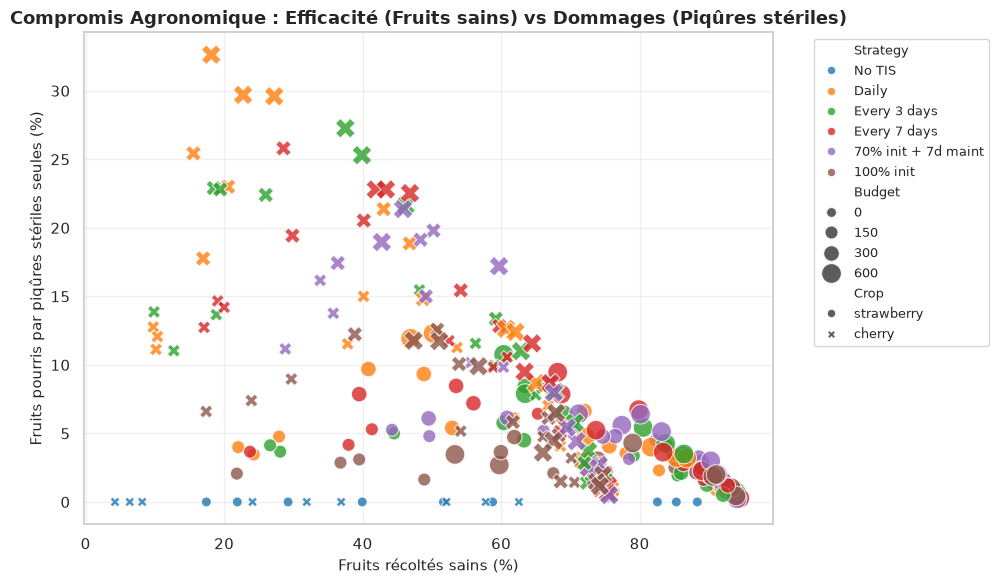

In [16]:
# ============================================================
# 1. GRAPHIQUE DE COMPROMIS (TRADE-OFF / EFFICACITÉ VS DOMMAGES)
# ============================================================
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

exp_df = pd.read_csv("resultats_experience_factorielle.csv")

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=exp_df[exp_df["Remating"] == "preference"],
    x="Harvested - clean (%)",
    y="Rotten - sterile only (%)",
    hue="Strategy",
    style="Crop",
    size="Budget",
    sizes=(50, 200),
    palette="tab10",
    alpha=0.8
)
plt.title("Compromis Agronomique : Efficacité (Fruits sains) vs Dommages (Piqûres stériles)", fontsize=13, fontweight='bold')
plt.xlabel("Fruits récoltés sains (%)", fontsize=11)
plt.ylabel("Fruits pourris par piqûres stériles seules (%)", fontsize=11)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=9)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

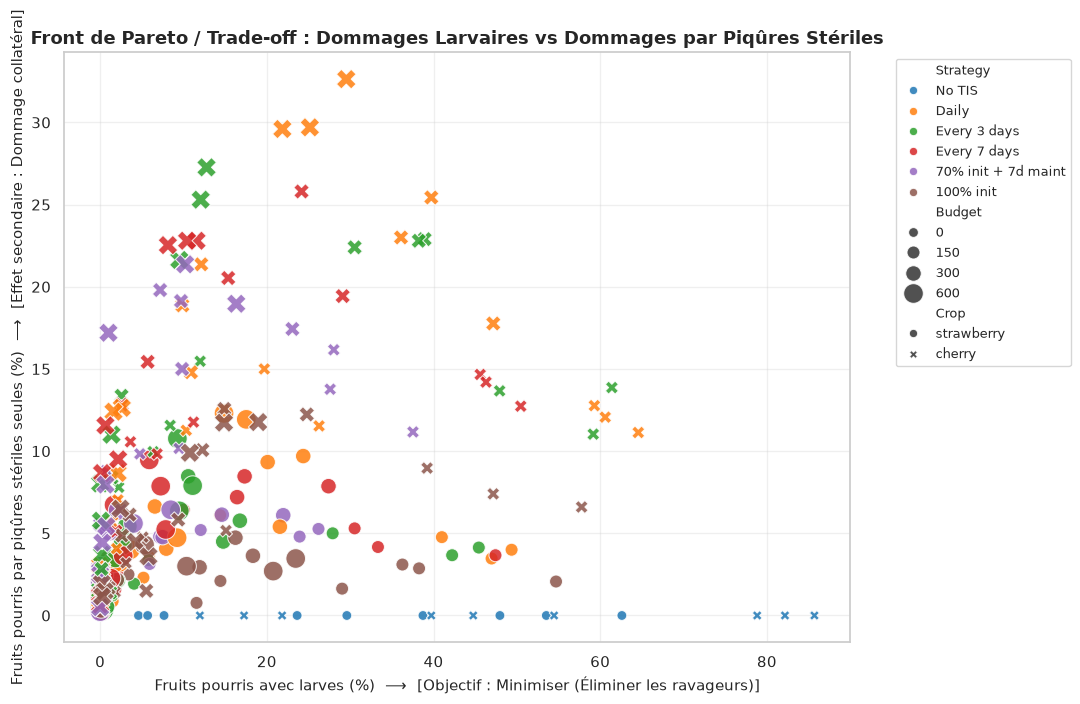

In [17]:
# ============================================================
# DIAGRAMME DE PARETO / TRADE-OFF : Dommages Larvaires vs Piqûres Stériles
# ============================================================
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Chargement des résultats factoriels
exp_df = pd.read_csv("resultats_experience_factorielle.csv")

plt.figure(figsize=(11, 7))

# On trace le trade-off : Pourrissement par larves vs Pourrissement par piqûres stériles seules
sns.scatterplot(
    data=exp_df[exp_df["Remating"] == "preference"],
    x="Rotten - larvae (%)",
    y="Rotten - sterile only (%)",
    hue="Strategy",
    style="Crop",
    size="Budget",
    sizes=(50, 200),
    palette="tab10",
    alpha=0.85
)

plt.title("Front de Pareto / Trade-off : Dommages Larvaires vs Dommages par Piqûres Stériles", fontsize=13, fontweight='bold')
plt.xlabel("Fruits pourris avec larves (%)  ⟶  [Objectif : Minimiser (Éliminer les ravageurs)]", fontsize=11)
plt.ylabel("Fruits pourris par piqûres stériles seules (%)  ⟶  [Effet secondaire : Dommage collatéral]", fontsize=11)

# Ajustement de la légende à l'extérieur du graphique
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=9)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

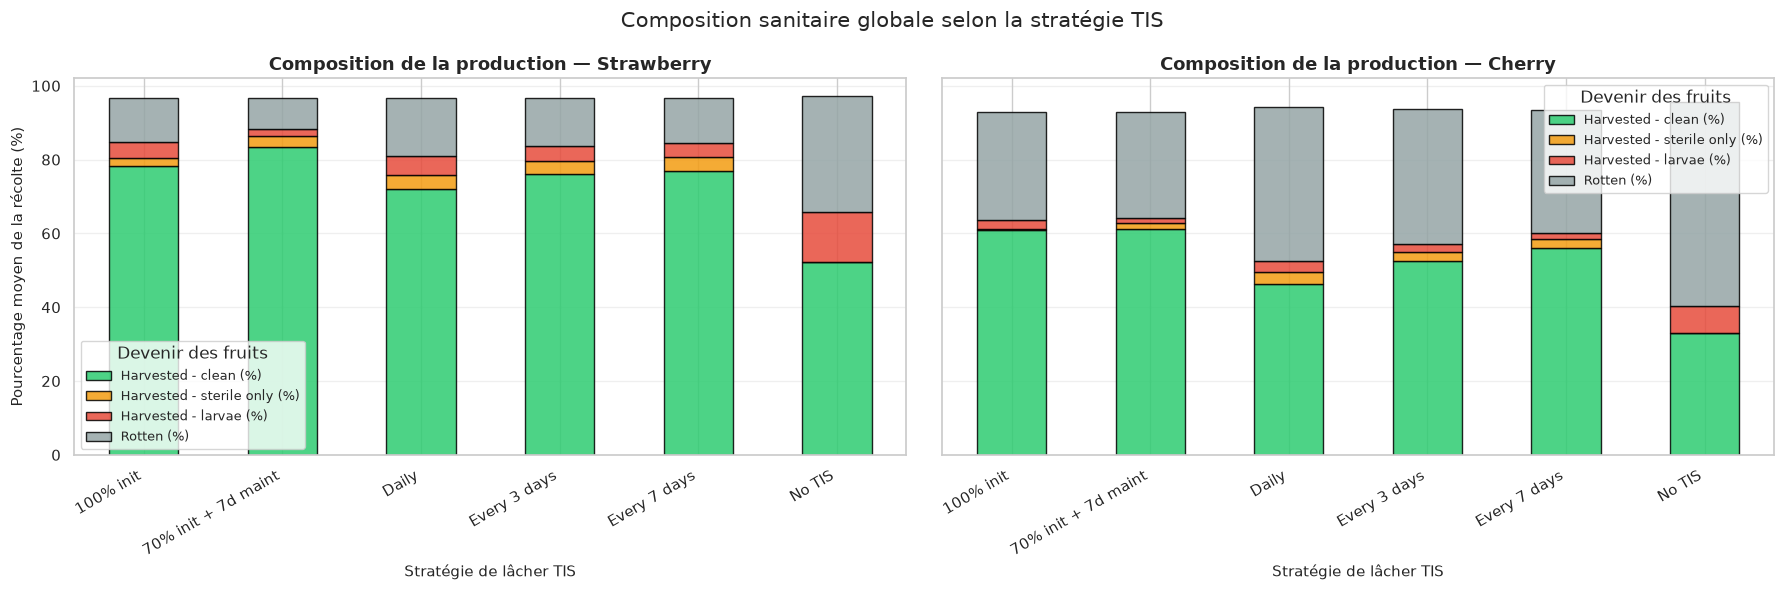

In [18]:
# ============================================================
# 2. BARRES EMPILÉES : COMPOSITION SANITAIRE DE LA PRODUCTION
# ============================================================
import pandas as pd
import matplotlib.pyplot as plt

exp_df = pd.read_csv("resultats_experience_factorielle.csv")

cols_comp = [
    "Harvested - clean (%)", 
    "Harvested - sterile only (%)", 
    "Harvested - larvae (%)", 
    "Rotten (%)"
]
existing_cols = [c for c in cols_comp if c in exp_df.columns]
comp_df = exp_df.groupby(["Crop", "Strategy"])[existing_cols].mean()

fig, axes = plt.subplots(1, 2, figsize=(18, 6), sharey=True)
colors_bar = ["#2ecc71", "#f39c12", "#e74c3c", "#95a5a6"]

for idx, c_name in enumerate(["strawberry", "cherry"]):
    ax = axes[idx]
    sub_data = comp_df.loc[c_name]
    sub_data.plot(
        kind="bar", 
        stacked=True, 
        ax=ax, 
        color=colors_bar[:len(existing_cols)],
        edgecolor="black",
        alpha=0.85
    )
    ax.set_title(f"Composition de la production — {c_name.capitalize()}", fontsize=13, fontweight='bold')
    ax.set_xlabel("Stratégie de lâcher TIS", fontsize=11)
    ax.set_ylabel("Pourcentage moyen de la récolte (%)", fontsize=11)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha="right")
    ax.legend(title="Devenir des fruits", fontsize=9)
    ax.grid(True, axis='y', alpha=0.3)

plt.suptitle("Composition sanitaire globale selon la stratégie TIS", fontsize=15, y=0.98)
plt.tight_layout()
plt.show()

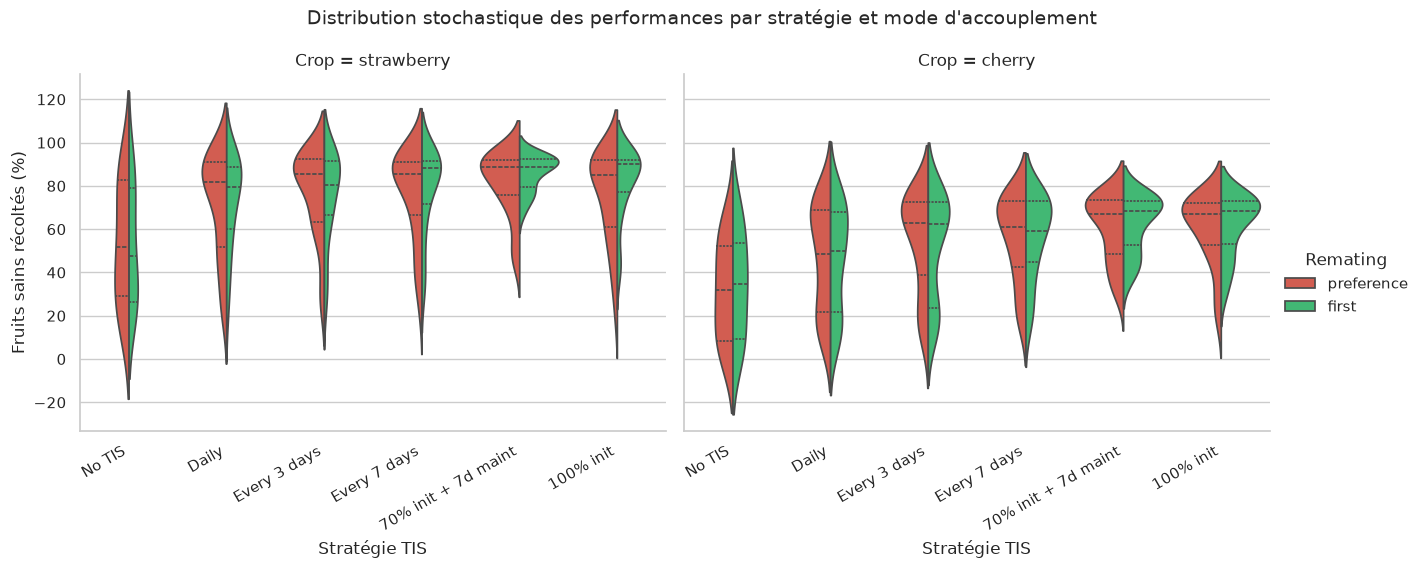

In [19]:
# ============================================================
# 3. VIOLIN PLOTS : DISTRIBUTION ET VARIABILITÉ STOCHASTIQUE
# ============================================================
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

exp_df = pd.read_csv("resultats_experience_factorielle.csv")
strat_order = ["No TIS", "Daily", "Every 3 days", "Every 7 days", "70% init + 7d maint", "100% init"]

g = sns.catplot(
    data=exp_df,
    x="Strategy",
    y="Harvested - clean (%)",
    hue="Remating",
    order=[s for s in strat_order if s in exp_df["Strategy"].unique()],
    col="Crop",
    kind="violin",
    split=True,
    palette={"preference": "#e74c3c", "first": "#2ecc71"},
    height=5,
    aspect=1.3,
    inner="quart"
)
g.set_xticklabels(rotation=30, ha="right")
g.set_axis_labels("Stratégie TIS", "Fruits sains récoltés (%)")
g.fig.subplots_adjust(top=0.85)
g.fig.suptitle("Distribution stochastique des performances par stratégie et mode d'accouplement", fontsize=14)
plt.show()

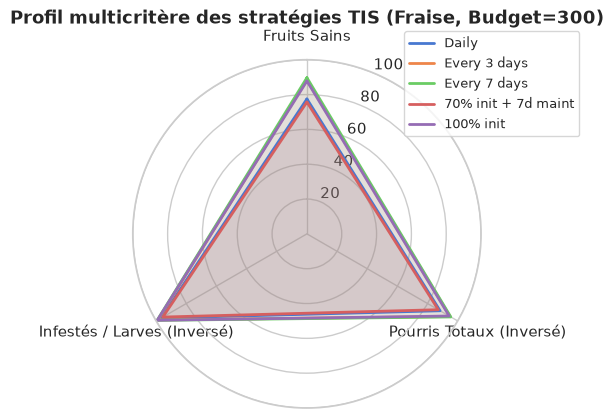

In [20]:
# ============================================================
# 4. DIAGRAMME RADAR : PROFIL MULTICRITÈRE DES STRATÉGIES (FRAISE)
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

exp_df = pd.read_csv("resultats_experience_factorielle.csv")

sub_radar = exp_df[
    (exp_df["Crop"] == "strawberry") & 
    (exp_df["Invasion"] == "Moyenne (10 W : 10 F)") & 
    (exp_df["Remating"] == "preference") &
    (exp_df["Budget"] == 300)
]

labels = ["Fruits Sains", "Pourris Totaux (Inversé)", "Infestés / Larves (Inversé)"]
radar_data = []
strategies = sub_radar["Strategy"].unique()

for strat in strategies:
    row = sub_radar[sub_radar["Strategy"] == strat].mean(numeric_only=True)
    vals = [
        row.get("Harvested - clean (%)", 0),
        max(0, 100 - row.get("Rotten (%)", 0)),
        max(0, 100 - row.get("Harvested - larvae (%)", 0))
    ]
    radar_data.append(vals)

angles = np.linspace(0, 2 * np.pi, len(labels), endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(6, 6), subplot_kw=dict(polar=True))

for i, strat in enumerate(strategies):
    values = radar_data[i]
    values += values[:1]
    ax.plot(angles, values, linewidth=2, label=strat)
    ax.fill(angles, values, alpha=0.1)

ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)
ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels, fontsize=11)
ax.set_ylim(0, 100)
ax.set_title("Profil multicritère des stratégies TIS (Fraise, Budget=300)", fontsize=13, fontweight='bold', y=1.08)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1), fontsize=9)
plt.tight_layout()
plt.show()

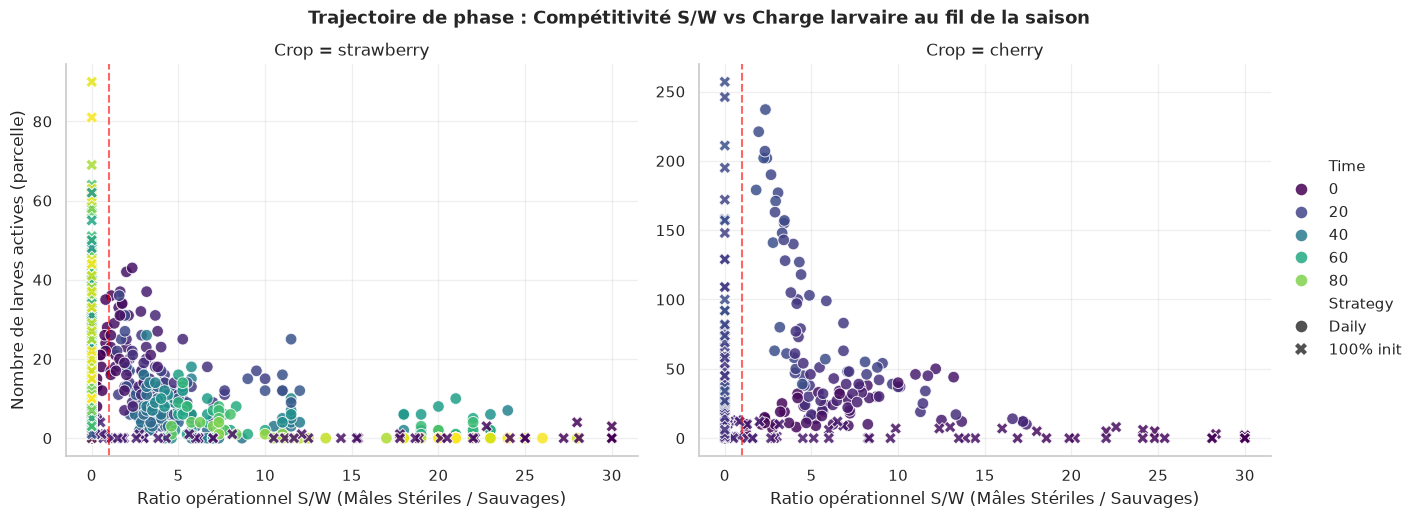

In [21]:
# ============================================================
# 5. PLAN DE PHASE AMÉLIORÉ : Trajectoire S/W vs Larves (Coloré par le Temps)
# ============================================================
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

dyn_df = pd.read_csv("dynamiques_temporelles_journalieres.csv")

if "SW_Ratio" not in dyn_df.columns:
    dyn_df["SW_Ratio"] = dyn_df["Sterile_males"] / np.maximum(1, dyn_df["Wild_males"])

sub_phase = dyn_df[
    (dyn_df["Strategy"].isin(["Daily", "100% init"])) & 
    (dyn_df["Remating"] == "preference") &
    (dyn_df["Budget"] == 300)
]

# Utilisation de relplot pour séparer Fraise et Cerise dans des sous-graphiques distincts
g = sns.relplot(
    data=sub_phase,
    x="SW_Ratio",
    y="Larvae",
    hue="Time",         # Le gradient de couleur indique le déroulement des jours (du début à la fin)
    col="Crop",         # Sépare Fraise et Cerise pour une clarté optimale
    style="Strategy",   # Différencie les stratégies par la forme des points
    kind="scatter",
    palette="viridis",  # Palette de couleur fluide pour le temps
    alpha=0.85,
    s=70,
    height=5,
    aspect=1.3,
    facet_kws={'sharex': False, 'sharey': False}
)

g.set_axis_labels("Ratio opérationnel S/W (Mâles Stériles / Sauvages)", "Nombre de larves actives (parcelle)")
g.fig.suptitle("Trajectoire de phase : Compétitivité S/W vs Charge larvaire au fil de la saison", fontsize=13, fontweight='bold', y=1.03)

# Ajout d'une ligne de repère pour la parité 1:1 sur chaque panneau
for ax in g.axes.flat:
    ax.axvline(1.0, color='red', linestyle='--', alpha=0.6, label="Parité 1:1")
    ax.grid(True, alpha=0.3)

plt.show()